# Section correction

1. Response-matrix correction
2. RCDS
3. RCDS+BO
4. RCDS (response-matrix directions)
5. RCDS+BO (response-matrix directions)
6. BO
7. RL (PPO)

## Import

In [1]:
from copy import deepcopy
from pathlib import Path
import os
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from threadpoolctl import threadpool_limits

get_ipython().run_line_magic("matplotlib", "inline")
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / "work" / "section_response.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the optimisation project or its work directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from score import sample_beam as sample_score_beam
from work.nominal_machine import load_lattice as load_model_lattice, load_beam as load_nominal_beam
from work.beam_tuning import rcds_search, sample_beam as sample_kickoff_beam
from work.beamline_tuning import (
    apply_knobs, 
    beam_moments,
    track_interval,
)
from work.section_response import (
    build_response_model,
    model_search_directions, direction_intervals,
    ideal_kickoff_beam,
    make_section_plan,
    perturb_normalized_start,
    iterative_response_search,
    track_to_boundary,
    transverse_state,
)
from work.section_measurement import (
    SectionSession, section_readout, section_value as local_value, full_bo_search,
)
from work.rl_tuning import ActorCritic, PPOConfig, train_ppo
from work.section_rl import (
    SectionRLConfig,
    SectionRLEnv,
    run_section_policy,
)

SEED = 101
FAST_RUN = os.environ.get("OPTIMISATION_SMOKE") == "1"
N_BEAMS = 2 if FAST_RUN else 4
NUM_PARTICLES = 750 if FAST_RUN else 10_0000
MEASUREMENT_BUDGET = 6 if FAST_RUN else 128
READOUT_NOISE = 0.0
START_ERROR_FRACTION = 0.05
RESPONSE_STEP = 0.025
RESPONSE_RIDGE = 1e-4
RESPONSE_LEARNING_RATE = 0.1
RESPONSE_STEPS = MEASUREMENT_BUDGET - 1  # one initial image, then one per update
RESPONSE_SOLVE_MODE = "block"
SCORE_BEAM_SEVERITY = 0.5

INITIAL_SCREEN = "cla_s04_sim_aper_01"
FINAL_SCREEN = "cla_s04_dia_scr_03"
PRIMARY_BEAM_SOURCE = "auto"
SECTION_MODEL = "nominal"  # "gpsr": scan settings; "scorer": legacy benchmark optics
SECTION_DETAILED_APERTURES = True
SECTION_BEAM_SEVERITY = SCORE_BEAM_SEVERITY


def load_section_lattice():
    # Independent fresh reference/plant copies; plant setting errors are applied via start.
    return load_model_lattice(model=SECTION_MODEL, errors=False,
                              apertures=SECTION_DETAILED_APERTURES, end=None)


def sample_section_input(configuration, reference_lattice, seed, num_particles, severity):
    source = configuration["beam_source"]
    if source == "kickoff":
        if severity == 0:
            with torch.random.fork_rng():
                torch.manual_seed(seed)
                return ideal_kickoff_beam(num_particles)
        return sample_kickoff_beam(seed, num_particles)
    if source == "nominal":
        root = load_nominal_beam(num_particles, seed=seed, severity=severity)
    elif source == "score":
        root = sample_score_beam(np.random.default_rng(seed), num_particles=num_particles, severity=severity)
    else:
        raise ValueError(f"Unknown beam source: {source}")
    return track_to_boundary(reference_lattice, root, configuration["input_screen"])


ENABLE_EXTRA_SECTION = os.environ.get("OPTIMISATION_EXTRA_SECTION") == "1"
EXTRA_SECTION_CONFIGS = [
    dict(
        name="S06 to S07",
        input_screen="cla_s06_dia_scr_02",
        output_screen="cla_s07_dia_scr_01",
        beam_source="auto",
    ),
] if ENABLE_EXTRA_SECTION else []
SECTION_CONFIGS = [
    dict(
        name=f"{INITIAL_SCREEN} to {FINAL_SCREEN}",
        input_screen=INITIAL_SCREEN,
        output_screen=FINAL_SCREEN,
        beam_source=PRIMARY_BEAM_SOURCE,
    ),
    *EXTRA_SECTION_CONFIGS,
]

METHODS = (
    "response matrix",
    "full BO",
    "RCDS",
    "RCDS+BO",
    "RCDS + response directions",
    "RCDS+BO + response directions",
)
FULL_BO_ACQUISITION = "ei_then_ucb"  # alternatives: "ei", "ucb"
FULL_BO_SWITCH_AT = None  # zero-based image index; None -> MEASUREMENT_BUDGET // 2
BO_UCB_BETA = 1.0
RCDS_BO_OPTIONS = dict(no_ucb=16, no_ei=16, ei_first=True, nr=4, rs=32, beta=BO_UCB_BETA, use_parabola=False)


# RL is trained independently for every section because the number of knobs can differ.
RL_SIMULATION_BEAMS = 2 if FAST_RUN else 4
RL_PRETRAIN_ITERATIONS = 1 if FAST_RUN else 128
RL_PRETRAIN_EPISODES = 2 if FAST_RUN else 16
RL_ADAPT_ITERATIONS = 1 if FAST_RUN else 8
RL_ADAPT_EPISODES = 1
RL_HORIZON = 2 if FAST_RUN else 8
RL_MAX_KNOB_STEP = 0.12
RL_PHYSICS_WEIGHT = 0.7  # zero recovers ordinary PPO
RL_HIDDEN = 32 if FAST_RUN else 64
assert N_BEAMS >= 2, "Need an adaptation beam plus at least one held-out beam"
assert RL_HORIZON + 1 <= MEASUREMENT_BUDGET
assert 0 <= RESPONSE_STEPS < MEASUREMENT_BUDGET
assert len({c["name"] for c in SECTION_CONFIGS}) == len(SECTION_CONFIGS)
for configuration in SECTION_CONFIGS:
    if configuration["beam_source"] == "auto":
        configuration["beam_source"] = (
            "score" if SECTION_MODEL == "scorer" else "nominal"
        )
    if configuration["beam_source"] == "kickoff" and configuration["input_screen"] != "cla_s04_sim_aper_01":
        raise ValueError("Kickoff beam is defined only at the S04 entrance; use score or auto")

torch.set_num_threads(1)
thread_limits = threadpool_limits(limits=1)
np.random.seed(SEED)
torch.manual_seed(SEED)

print({
    "sections": [case["name"] for case in SECTION_CONFIGS],
    "section lattice": SECTION_MODEL,
    "detailed apertures": SECTION_DETAILED_APERTURES if SECTION_MODEL != "scorer" else "scorer apertures",
    "input beam sources": [case["beam_source"] for case in SECTION_CONFIGS],
    "beams per section": N_BEAMS,
    "online RCDS budget": MEASUREMENT_BUDGET,
    "readout noise": READOUT_NOISE,
    "response solve": RESPONSE_SOLVE_MODE,
    "response learning rate": RESPONSE_LEARNING_RATE,
    "response updates": RESPONSE_STEPS,
    "RL pretrain iterations": RL_PRETRAIN_ITERATIONS,
    "RL one-beam adaptation iterations": RL_ADAPT_ITERATIONS,
    "RL deployment measurements": RL_HORIZON + 1,
    "physics action weight": RL_PHYSICS_WEIGHT,
})

# raw_svd reproduces the old basis; clean_svd only removes tiny cross-components.
DIRECTION_MODE = "boundary_aware"
from work.section_sequence import plan_screen_sequence, optimize_section, correct_screen_sequence
from work.beamline_tuning import is_physical_screen, knobs_for_elements

# Simulation pretraining resolution; adaptation and evaluation keep NUM_PARTICLES.
RL_TRAIN_PARTICLES = min(NUM_PARTICLES, 4096)
RL_FAST_TRACKING = True  # False restores the original screen-copy tracking path.
RL_PROGRESS_EVERY = 8


{'sections': ['cla_s04_sim_aper_01 to cla_s04_dia_scr_03'], 'section lattice': 'nominal', 'detailed apertures': True, 'input beam sources': ['nominal'], 'beams per section': 4, 'online RCDS budget': 128, 'readout noise': 0.0, 'response solve': 'block', 'response learning rate': 0.1, 'response updates': 127, 'RL pretrain iterations': 128, 'RL one-beam adaptation iterations': 8, 'RL deployment measurements': 9, 'physics action weight': 0.7}


## 1. New nominal lattice, input beam, target, and section controls

`SECTION_MODEL="nominal"` loads the new nominal-model lattice-file strengths directly, with
`data/clara/lattice_data/apertures.json` enabled. `"gpsr"` selects the reconstruction scan tune;
`"scorer"` explicitly selects the older benchmark loader and its own apertures. This setting
is shared by classical tuning, response-model construction, diagnostics, PPO pretraining,
one-beam adaptation and held-out transfer. The final full-machine experiment has its own
`FULL_MODEL` setting.

The default `beam_source="auto"` now means the measured nominal 6D distribution for nominal/GPSR
optics, including at S04. The ideal root beam is sampled from `nominal_model/initial_distribution.npz`
at the S02 marker and propagated through the chosen reference lattice to the selected entrance.
Varied beams use the same distribution with explicit affine jitter controlled by
`SECTION_BEAM_SEVERITY`; full cross-coordinate correlations are retained. The target and response
matrix use the ideal beam and unperturbed optics. Actual correction starts at perturbed normalized
magnet settings. This isolated comparison does not add hidden magnet misalignments.

Explicit `beam_source="kickoff"` remains available only at the S04 entrance for legacy experiments;
`"score"` selects the scorer input distribution. Neither is used by default with the new lattice.
All quadrupole and corrector controls strictly between the named boundaries are normalized to [0,1].
Only exit-screen position and projected sizes enter the objective; simulated input covariance is
shown for diagnostics, not supplied as a measured state to the tuner.


In [2]:
def make_section_beams(configuration, reference_lattice):
    ideal = sample_section_input(configuration, reference_lattice, SEED, NUM_PARTICLES, 0.)
    beams = [sample_section_input(configuration, reference_lattice, SEED+100+index,
                                  NUM_PARTICLES, SECTION_BEAM_SEVERITY)
             for index in range(N_BEAMS)]
    return ideal, beams


section_models = {}
plan_rows, input_state_rows = [], []
for section_index, configuration in enumerate(SECTION_CONFIGS):
    reference_lattice = load_section_lattice()
    plan = make_section_plan(
        reference_lattice,
        configuration["input_screen"],
        configuration["output_screen"],
        include_rf_phase=False,
    )
    ideal_input, test_beams = make_section_beams(configuration, reference_lattice)
    model = build_response_model(
        reference_lattice,
        plan,
        ideal_input,
        step=RESPONSE_STEP,
    )
    start = perturb_normalized_start(
        model.center,
        seed=SEED + section_index,
        fraction=START_ERROR_FRACTION,
    )
    centre, covariance = transverse_state(ideal_input)
    counts = pd.Series([knob.kind for knob in plan.knobs]).value_counts()
    plan_rows.append(dict(
        section=configuration["name"],
        input_screen=plan.input_screen,
        output_screen=plan.output_screen,
        beam_source=configuration["beam_source"],
        knobs=len(plan.knobs),
        quadrupoles=int(counts.get("quadrupole", 0)),
        correctors=int(counts.get("corrector", 0)),
        offline_response_tracks=1 + 2 * len(plan.knobs),
    ))
    input_state_rows.append(dict(
        section=configuration["name"],
        mu_x_um=centre[0] * 1e6,
        mu_px_urad=centre[1] * 1e6,
        mu_y_um=centre[2] * 1e6,
        mu_py_urad=centre[3] * 1e6,
        sigma_x_um=np.sqrt(covariance[0, 0]) * 1e6,
        sigma_px_urad=np.sqrt(covariance[1, 1]) * 1e6,
        sigma_y_um=np.sqrt(covariance[2, 2]) * 1e6,
        sigma_py_urad=np.sqrt(covariance[3, 3]) * 1e6,
        cov_xpx=covariance[0, 1],
        cov_ypy=covariance[2, 3],
    ))
    section_models[configuration["name"]] = dict(
        configuration=configuration,
        plan=plan,
        model=model,
        start=start,
        beams=test_beams,
        ideal_input=ideal_input,
    )

display(pd.DataFrame(plan_rows))
print("Ideal input states reconstructed from particles:")
display(pd.DataFrame(input_state_rows))

for name, item in section_models.items():
    print(f"\n{name} target [mu_x, mu_y, sigma_x, sigma_y] in um:")
    print(np.round(item["model"].target * 1e6, 3))
    display(pd.DataFrame({
        "knob": [knob.label for knob in item["plan"].knobs],
        "kind": [knob.kind for knob in item["plan"].knobs],
        "reference_u": item["model"].center,
        "start_u": item["start"],
    }))

,section,input_screen,output_screen,beam_source,knobs,quadrupoles,correctors,offline_response_tracks
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,cla_s04_sim_aper_01,cla_s04_dia_scr_03,nominal,8,4,4,17


Ideal input states reconstructed from particles:


,section,mu_x_um,mu_px_urad,mu_y_um,mu_py_urad,sigma_x_um,sigma_px_urad,sigma_y_um,sigma_py_urad,cov_xpx,cov_ypy
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,-139.550507,-14.798824,-5.541915,-0.259095,1050.741588,107.412312,1569.760586,70.644225,1.122659e-07,1.103856e-07



cla_s04_sim_aper_01 to cla_s04_dia_scr_03 target [mu_x, mu_y, sigma_x, sigma_y] in um:
[-157.61    -7.258 1172.948 2046.786]


,knob,kind,reference_u,start_u
0,cla_s04_mag_hvcor_01.horizontal_angle,corrector,0.587002,0.547495
1,cla_s04_mag_hvcor_01.vertical_angle,corrector,0.560676,0.458945
2,cla_s04_mag_quad_01.k1,quadrupole,0.346175,0.376340
3,cla_s04_mag_quad_02.k1,quadrupole,1.000000,1.000000
4,cla_s04_mag_quad_03.k1,quadrupole,0.000000,0.000000
5,cla_s04_mag_quad_04.k1,quadrupole,0.000000,0.018366
6,cla_s04_mag_hvcor_02.horizontal_angle,corrector,0.925825,1.000000
7,cla_s04_mag_hvcor_02.vertical_angle,corrector,0.104243,0.157283


In [3]:
screen_lattice = load_section_lattice()
screen_rows = [dict(index=-1, name="cla_s02_dia_scr_01", kind="virtual scorer input")]
for index, element in enumerate(screen_lattice.elements):
    if isinstance(element, __import__("cheetah").Screen):
        screen_rows.append(dict(index=index, name=element.name,
                                kind="physical screen" if is_physical_screen(element) else "simulation marker / other"))
display(pd.DataFrame(screen_rows))

,index,name,kind
0,-1,cla_s02_dia_scr_01,virtual scorer input
1,9,cla_s02_dia_bpm_01,simulation marker / other
2,16,cla_s02_dia_scr_01,physical screen
3,26,cla_s02_sim_aper_02,simulation marker / other
4,34,cla_s02_dia_scr_02,physical screen
...,...,...,...
124,781,cla_fed_dia_bpm_01,simulation marker / other
125,784,cla_fed_dia_scr_01,physical screen
126,791,cla_fed_dia_bpm_02,simulation marker / other
127,798,cla_fed_dia_scr_02,physical screen


## 2. Response matrices and physics directions

For normalized controls u and scaled output y/s, central finite differences form

J_ki = d(y_k/s_k) / d u_i.

Orbit is scaled by 100 micrometres. Shape is scaled by its ideal output size, with a
100 micrometre floor. The notebook displays the full matrix and the physically motivated blocks:
correctors to orbit and quadrupoles to shape. The block response correction solves shape first
with quadrupoles and then orbit with correctors. The coupled option solves all entries together.

The rows of V-transpose from a full SVD of J are used as initial RCDS directions. They are the
eigenvectors of the local Gauss-Newton matrix J-transpose J. This is a response-aligned,
orthonormal basis; it is not guaranteed to remain conjugate once nonlinearities or model error
become large. Also, the optimized L1 objective has no fixed quadratic Hessian, so these
are model-derived search directions, not guaranteed conjugate directions for this objective.
Full SVD retains null-space directions so RCDS still receives one direction per
control.



In [4]:
OUTPUT_LABELS = ("mu_x", "mu_y", "sigma_x", "sigma_y")
response_diagnostics = []
OUTPUT_DIR = ROOT / "work" / "experiment_outputs" / "section_models" / SECTION_MODEL / ("apertures" if SECTION_DETAILED_APERTURES else "no_apertures")
if FAST_RUN:
    OUTPUT_DIR = OUTPUT_DIR / "section_smoke"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, item in section_models.items():
    plan, model = item["plan"], item["model"]
    labels = [knob.label for knob in plan.knobs]
    matrix = pd.DataFrame(model.response, index=OUTPUT_LABELS, columns=labels)
    print(f"\n{name}: complete scaled response")
    display(matrix.style.background_gradient(cmap="coolwarm", axis=None))

    correctors = [index for index, knob in enumerate(plan.knobs) if knob.kind == "corrector"]
    quadrupoles = [index for index, knob in enumerate(plan.knobs) if knob.kind == "quadrupole"]
    print("Corrector-to-orbit block:")
    display(matrix.iloc[:2, correctors])
    print("Quadrupole-to-shape block:")
    display(matrix.iloc[2:, quadrupoles])

    active = model.singular_values[model.singular_values > 1e-10]
    response_diagnostics.append(dict(
        section=name,
        rows=model.response.shape[0],
        controls=model.response.shape[1],
        numerical_rank=int(np.linalg.matrix_rank(model.response)),
        largest_singular=model.singular_values[0],
        smallest_active_singular=active[-1],
        active_condition=model.singular_values[0] / active[-1],
        direction_orthogonality_error=np.max(np.abs(
            model.directions @ model.directions.T - np.eye(len(plan.knobs))
        )),
    ))

    slug = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    path = OUTPUT_DIR / f"{slug}_ideal_response.npz"
    np.savez(
        path,
        lattice_model=np.asarray(SECTION_MODEL),
        detailed_apertures=np.asarray(SECTION_DETAILED_APERTURES),
        beam_source=np.asarray(item["configuration"]["beam_source"]),
        input_screen=np.asarray(plan.input_screen),
        output_screen=np.asarray(plan.output_screen),
        knob_labels=np.asarray(labels, dtype="U96"),
        knob_kinds=np.asarray([knob.kind for knob in plan.knobs], dtype="U16"),
        center=model.center,
        target=model.target,
        scale=model.scale,
        response=model.response,
        directions=model.directions,
        singular_values=model.singular_values,
    )
    item["response_file"] = path
    print("Saved:", path)

display(pd.DataFrame(response_diagnostics))

# Inspect the actual feasible line, not just orthogonality of the saved SVD.
direction_rows = []
for name, item in section_models.items():
    model, start = item["model"], item["start"]
    for mode in ("raw_svd", "clean_svd", "boundary_aware"):
        basis = model_search_directions(model, start, mode=mode)
        intervals = direction_intervals(start, basis)
        for index, (row, (lower, upper)) in enumerate(zip(basis, intervals)):
            direction_rows.append(dict(section=name, basis=mode, direction=index,
                                       lower_alpha=lower, upper_alpha=upper,
                                       blocked=upper-lower < 1e-8,
                                       model_gain=np.linalg.norm(model.response @ row)))
    # Store the basis actually passed to RCDS, with knob order and normalization metadata.
    item["search_directions"] = model_search_directions(model, start, mode=DIRECTION_MODE)
    np.savez(OUTPUT_DIR / (re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_") + "_search_directions.npz"),
             directions=item["search_directions"], mode=DIRECTION_MODE, start=start,
             knob_labels=[k.label for k in item["plan"].knobs],
             lower=[k.lower for k in item["plan"].knobs], upper=[k.upper for k in item["plan"].knobs])
display(pd.DataFrame(direction_rows))



cla_s04_sim_aper_01 to cla_s04_dia_scr_03: complete scaled response


,cla_s04_mag_hvcor_01.horizontal_angle,cla_s04_mag_hvcor_01.vertical_angle,cla_s04_mag_quad_01.k1,cla_s04_mag_quad_02.k1,cla_s04_mag_quad_03.k1,cla_s04_mag_quad_04.k1,cla_s04_mag_hvcor_02.horizontal_angle,cla_s04_mag_hvcor_02.vertical_angle
mu_x,57.215229,0.000000,3.488018,2.248341,0.154419,0.138424,6.397822,0.000000
mu_y,0.000000,29.605771,-0.124115,-0.086778,-0.006883,-0.006497,0.000000,4.553099
sigma_x,0.000000,0.000000,-2.235464,-1.438123,-0.098583,-0.088198,0.000000,0.000000
sigma_y,0.000000,0.000000,1.716570,1.199088,0.095053,0.089661,0.000000,0.000000


Corrector-to-orbit block:


,cla_s04_mag_hvcor_01.horizontal_angle,cla_s04_mag_hvcor_01.vertical_angle,cla_s04_mag_hvcor_02.horizontal_angle,cla_s04_mag_hvcor_02.vertical_angle
mu_x,57.215229,0.000000,6.397822,0.000000
mu_y,0.000000,29.605771,0.000000,4.553099


Quadrupole-to-shape block:


,cla_s04_mag_quad_01.k1,cla_s04_mag_quad_02.k1,cla_s04_mag_quad_03.k1,cla_s04_mag_quad_04.k1
sigma_x,-2.235464,-1.438123,-0.098583,-0.088198
sigma_y,1.716570,1.199088,0.095053,0.089661


Saved: /home/morozov/SOFT/artifact-hackathon-2026/challenges/optimisation/work/experiment_outputs/section_models/nominal/apertures/cla_s04_sim_aper_01_to_cla_s04_dia_scr_03_ideal_response.npz


,section,rows,controls,numerical_rank,largest_singular,smallest_active_singular,active_condition,direction_orthogonality_error
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,4,8,4,57.722082,0.066027,874.218866,5.551115e-16


,section,basis,direction,lower_alpha,upper_alpha,blocked,model_gain
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,raw_svd,0,-0.000000,0.000000,True,5.772208e+01
1,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,raw_svd,1,-0.000000,0.000000,True,2.995422e+01
2,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,raw_svd,2,-0.000000,0.000000,True,3.379373e+00
3,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,raw_svd,3,-0.000000,0.000000,True,6.602704e-02
4,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,raw_svd,4,-0.000000,0.693806,False,7.858125e-17
5,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,raw_svd,5,-0.000000,0.000000,True,1.359851e-16
6,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,raw_svd,6,-0.000000,0.000000,True,1.235897e-15
7,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,raw_svd,7,-0.000000,0.000000,True,3.610827e-16
8,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,clean_svd,0,-0.000000,0.000000,True,5.772208e+01
9,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,clean_svd,1,-0.000000,0.000000,True,2.995422e+01


## 3. Correction methods and measurement accounting

Every test starts from the same perturbed normalized setting for a section.

- Response correction uses the fixed matrix calculated from the **ideal input beam** and nominal
  section. It takes one starting image, then RESPONSE_STEPS measured correction steps. Each step
  uses the current exit residual to solve for a bounded full correction delta_u and applies only
  RESPONSE_LEARNING_RATE=0.1 of it: u_next = u + 0.1 * delta_u. A fresh exit-screen image is taken
  after every update. The actual input covariance is never supplied to the response model, and
  the matrix is not refitted from these images. The best measured setting across all steps is
  retained. Total cost is RESPONSE_STEPS + 1 images (the full budget by default).
- Full BO fits one GP over all normalized knobs, starting at the same setting. It uses EI
  for image indices i < FULL_BO_SWITCH_AT, then a confidence bound with BO_UCB_BETA=1.
  None selects half of the measurement budget. Index zero is the starting image; initial random
  samples take precedence over acquisition optimization. The per-image ledger records the actual
  phase (start/random/EI/LCB).
- For minimization, BoTorch UCB(maximize=False) maximizes -mu + sqrt(beta)*sigma.
  Full BO uses the equivalent scikit-optimize LCB, minimizing mu - sqrt(beta)*sigma.
  EI uses xi=0, matching improvement over the best observed value.
- RCDS+BO uses the same EI-then-UCB order within each 1D line search: no_ei EI steps,
  followed by no_ucb confidence-bound steps. Its EI is computed as LogEI for numerical stability.
  Set ei_first=False to restore the original UCB-then-EI order.
- RCDS and RCDS+BO receive the configured online budget. Their baseline versions use the identity
  basis.
- The direction-informed versions use DIRECTION_MODE (boundary-aware cleaned model rows by
  default), without changing the start point or budget.

No method receives the actual input beam centre or covariance. Those quantities are used only by
the simulator to create an unknown plant. Final clean moments are evaluated after selection for
diagnosis and are not passed back to an optimizer.

In [5]:
def section_value(moments, model, part="all"):
    return local_value(moments, model.target, model.scale, part)


def optics_diagnostics(output, item):
    center, covariance = transverse_state(output)
    ideal_center, ideal_covariance = item["ideal_exit_state"]
    scale = np.sqrt(np.maximum(np.diag(ideal_covariance), 1e-30))
    return dict(
        # Dimensionless RMS of all 16 covariance errors scaled by ideal rms coordinates.
        covariance_error=float(np.sqrt(np.mean(
            ((covariance - ideal_covariance) / np.outer(scale, scale))**2
        ))),
        angle_error_urad=float(np.mean(np.abs(center[[1, 3]] - ideal_center[[1, 3]])) * 1e6),
        survival=float(output.survival_probabilities.mean()),
    )


# Extra ideal propagation is a diagnostic simulation, not a response or machine shot.
for item in section_models.values():
    lattice = load_section_lattice()
    apply_knobs(lattice, item["plan"].knobs, item["model"].center)
    item["ideal_exit_state"] = transverse_state(track_interval(lattice, item["plan"], item["ideal_input"]))


def run_method(section_name, item, beam, beam_index, method):
    machine = load_section_lattice()
    plan = make_section_plan(
        machine,
        item["configuration"]["input_screen"],
        item["configuration"]["output_screen"],
        include_rf_phase=False,
    )
    model, start = item["model"], item["start"]
    session = SectionSession(
        machine,
        plan,
        beam,
        model.target,
        budget=MEASUREMENT_BUDGET,
        scale=model.scale,
        noise_fraction=READOUT_NOISE,
        seed=SEED + 50_000 + 100 * beam_index,
    )

    apply_knobs(machine, plan.knobs, start)
    initial_truth = section_readout(track_interval(machine, plan, beam))[0]

    optimize_section(
        session, model, start, method, seed=SEED + 100 * beam_index,
        response_steps=RESPONSE_STEPS, learning_rate=RESPONSE_LEARNING_RATE,
        response_mode=RESPONSE_SOLVE_MODE, ridge=RESPONSE_RIDGE,
        direction_mode=DIRECTION_MODE, rcds_bo_options=RCDS_BO_OPTIONS,
        bo_options=dict(acquisition=FULL_BO_ACQUISITION,
                        switch_at=FULL_BO_SWITCH_AT, beta=BO_UCB_BETA),
    )

    selected = session.best()["u"]
    apply_knobs(machine, plan.knobs, selected)
    output = track_interval(machine, plan, beam)
    final_truth = section_readout(output)[0]
    row = dict(
        section=section_name,
        beam=beam_index,
        method=method,
        **optics_diagnostics(output, item),
        online_measurements=len(session.records),
        initial_truth=section_value(initial_truth, model),
        best_observed=session.best()["value"],
        final_truth=section_value(final_truth, model),
        orbit_truth=section_value(final_truth, model, "orbit"),
        shape_truth=section_value(final_truth, model, "shape"),
        improved=section_value(final_truth, model) < section_value(initial_truth, model),
    )
    for j, label in enumerate(("mu_x", "mu_y", "sigma_x", "sigma_y")):
        row[f"target_{label}_um"] = model.target[j] * 1e6
        row[f"initial_{label}_um"] = initial_truth[j] * 1e6
        row[f"final_{label}_um"] = final_truth[j] * 1e6
    return row, session, selected


result_rows, sessions, selected_controls = [], {}, {}
for section_name, item in section_models.items():
    for beam_index, beam in enumerate(item["beams"]):
        for method in METHODS:
            row, session, selected = run_method(
                section_name, item, beam, beam_index, method
            )
            result_rows.append(row)
            sessions[section_name, beam_index, method] = session
            selected_controls[section_name, beam_index, method] = selected

results = pd.DataFrame(result_rows)
display(results[["section", "beam", "method", "online_measurements", "initial_truth", "best_observed", "final_truth"]].rename(columns={"initial_truth": "initial objective (clean)", "best_observed": "selected objective (noisy)", "final_truth": "final objective (clean)"}))
assert (results[results.method == "response matrix"].online_measurements == RESPONSE_STEPS + 1).all()
assert (
    results[results.method != "response matrix"].online_measurements
    == MEASUREMENT_BUDGET
).all()

/home/morozov/anaconda3/envs/code/lib/python3.14/site-packages/botorch/fit.py:241: OptimizationWarning: `scipy_minimize` terminated with status OptimizationStatus.FAILURE, displaying original message from `scipy.optimize.minimize`: ABNORMAL: 
  result = optimizer(mll, closure=closure, **optimizer_kwargs)
/home/morozov/anaconda3/envs/code/lib/python3.14/site-packages/botorch/fit.py:241: OptimizationWarning: `scipy_minimize` terminated with status OptimizationStatus.FAILURE, displaying original message from `scipy.optimize.minimize`: ABNORMAL: 
  result = optimizer(mll, closure=closure, **optimizer_kwargs)
/home/morozov/anaconda3/envs/code/lib/python3.14/site-packages/botorch/fit.py:241: OptimizationWarning: `scipy_minimize` terminated with status OptimizationStatus.FAILURE, displaying original message from `scipy.optimize.minimize`: ABNORMAL: 
  result = optimizer(mll, closure=closure, **optimizer_kwargs)


,section,beam,method,online_measurements,initial objective (clean),selected objective (noisy),final objective (clean)
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,0,response matrix,128,1.462156,0.004674,0.004674
1,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,0,full BO,128,1.462156,0.112408,0.112408
2,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,0,RCDS,128,1.462156,0.045519,0.045519
3,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,0,RCDS+BO,128,1.462156,0.059832,0.059832
4,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,0,RCDS + response directions,128,1.462156,0.007672,0.007672
5,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,0,RCDS+BO + response directions,128,1.462156,0.034015,0.034015
6,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,response matrix,128,0.938416,0.010153,0.010153
7,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,full BO,128,0.938416,0.146866,0.146866
8,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,RCDS,128,0.938416,0.018638,0.018638
9,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,RCDS+BO,128,0.938416,0.024342,0.024342


In [6]:
# The objective is dimensionless mean absolute scaled error, not the official score.
# Positions use 100 um scales; sizes use max(ideal size, 100 um).
objective_columns = {"initial_truth": "initial objective (clean)",
                     "best_observed": "selected objective (noisy)",
                     "final_truth": "final objective (clean)",
                     "orbit_truth": "orbit objective (clean)",
                     "shape_truth": "size objective (clean)"}
display(results[["beam", "method", "online_measurements", *objective_columns]].rename(columns=objective_columns))
moment_comparison = results.melt(id_vars=["section", "beam", "method"],
    value_vars=[f"{phase}_{label}_um" for label in OUTPUT_LABELS for phase in ("target", "initial", "final")],
    var_name="moment and phase", value_name="value [um]")
display(moment_comparison)


,beam,method,online_measurements,initial objective (clean),selected objective (noisy),final objective (clean),orbit objective (clean),size objective (clean)
0,0,response matrix,128,1.462156,0.004674,0.004674,0.000006,9.341679e-03
1,0,full BO,128,1.462156,0.112408,0.112408,0.171208,5.360774e-02
2,0,RCDS,128,1.462156,0.045519,0.045519,0.000332,9.070513e-02
3,0,RCDS+BO,128,1.462156,0.059832,0.059832,0.032914,8.675003e-02
4,0,RCDS + response directions,128,1.462156,0.007672,0.007672,0.006730,8.614887e-03
5,0,RCDS+BO + response directions,128,1.462156,0.034015,0.034015,0.053627,1.440341e-02
6,1,response matrix,128,0.938416,0.010153,0.010153,0.000012,2.029423e-02
7,1,full BO,128,0.938416,0.146866,0.146866,0.142540,1.511922e-01
8,1,RCDS,128,0.938416,0.018638,0.018638,0.010308,2.696741e-02
9,1,RCDS+BO,128,0.938416,0.024342,0.024342,0.018530,3.015296e-02


,section,beam,method,moment and phase,value [um]
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,0,response matrix,target_mu_x_um,-157.609902
1,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,0,full BO,target_mu_x_um,-157.609902
2,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,0,RCDS,target_mu_x_um,-157.609902
3,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,0,RCDS+BO,target_mu_x_um,-157.609902
4,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,0,RCDS + response directions,target_mu_x_um,-157.609902
...,...,...,...,...,...
283,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,3,full BO,final_sigma_y_um,1954.663079
284,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,3,RCDS,final_sigma_y_um,2062.447136
285,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,3,RCDS+BO,final_sigma_y_um,2203.775570
286,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,3,RCDS + response directions,final_sigma_y_um,2078.290796


In [7]:
summary = results.groupby(["section", "method"], sort=False).agg(
    mean_initial=("initial_truth", "mean"),
    mean_final=("final_truth", "mean"),
    worst_final=("final_truth", "max"),
    mean_orbit=("orbit_truth", "mean"),
    mean_shape=("shape_truth", "mean"),
    improvement_rate=("improved", "mean"),
    mean_online_measurements=("online_measurements", "mean"),
).reset_index()
summary["mean_reduction_percent"] = 100 * (
    1 - summary.mean_final / summary.mean_initial
)
summary["rank"] = summary.groupby("section").mean_final.rank()
display(summary.sort_values(["section", "rank"]))

direction_comparison = summary.pivot(
    index="section", columns="method", values="mean_final"
)
for algorithm in ("RCDS", "RCDS+BO"):
    direction_comparison[f"{algorithm} direction change [%]"] = 100 * (
        direction_comparison[f"{algorithm} + response directions"]
        / direction_comparison[algorithm]
        - 1
    )
print("Negative direction change means the response basis helped:")
display(direction_comparison[[
    "RCDS direction change [%]",
    "RCDS+BO direction change [%]",
]])

,section,method,mean_initial,mean_final,worst_final,mean_orbit,mean_shape,improvement_rate,mean_online_measurements,mean_reduction_percent,rank
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,response matrix,1.462906,0.003709,0.010153,0.000008,0.007409,1.0,128.0,99.746480,1.0
4,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS + response directions,1.462906,0.012221,0.018141,0.008332,0.016110,1.0,128.0,99.164624,2.0
2,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS,1.462906,0.026998,0.045519,0.003395,0.050601,1.0,128.0,98.154502,3.0
5,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS+BO + response directions,1.462906,0.039706,0.045635,0.032727,0.046685,1.0,128.0,97.285816,4.0
3,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS+BO,1.462906,0.042158,0.059832,0.018243,0.066073,1.0,128.0,97.118202,5.0
1,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,full BO,1.462906,0.116637,0.146866,0.121325,0.111949,1.0,128.0,92.027045,6.0


Negative direction change means the response basis helped:


method,RCDS direction change [%],RCDS+BO direction change [%]
section,,
cla_s04_sim_aper_01 to cla_s04_dia_scr_03,-54.734408,-5.816308


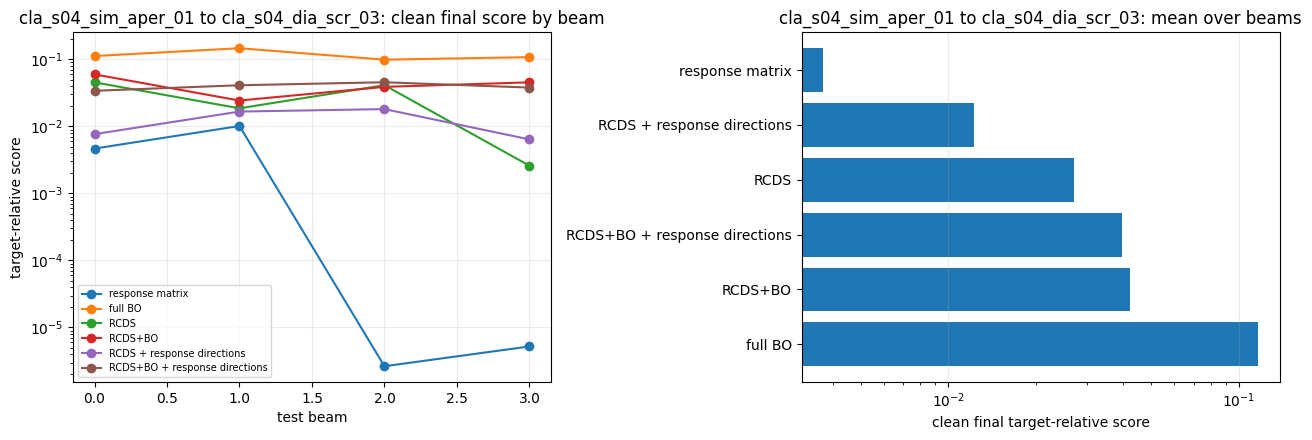

In [8]:
fig, axes = plt.subplots(
    len(section_models), 2,
    figsize=(13, 4.5 * len(section_models)),
    squeeze=False,
)
for row_index, section_name in enumerate(section_models):
    section_results = results[results.section == section_name]
    for method in METHODS:
        rows = section_results[section_results.method == method]
        axes[row_index, 0].plot(
            rows.beam,
            rows.final_truth,
            "o-",
            label=method,
        )
    axes[row_index, 0].set(
        title=f"{section_name}: clean final score by beam",
        xlabel="test beam",
        ylabel="target-relative score",
        yscale="log",
    )
    axes[row_index, 0].grid(alpha=.25)
    axes[row_index, 0].legend(fontsize=7)

    methods = summary[summary.section == section_name].sort_values("rank")
    axes[row_index, 1].barh(methods.method, methods.mean_final)
    axes[row_index, 1].invert_yaxis()
    axes[row_index, 1].set(
        title=f"{section_name}: mean over beams",
        xlabel="clean final target-relative score",
        xscale="log",
    )
    axes[row_index, 1].grid(alpha=.25, axis="x")
plt.tight_layout()
plt.show()

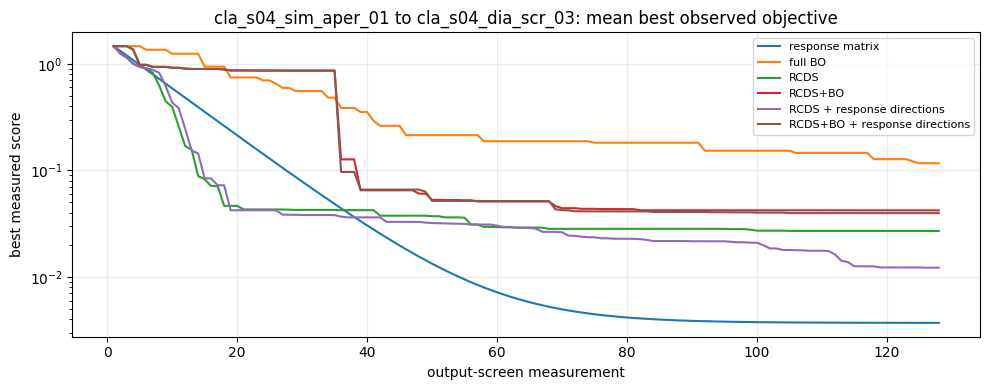

In [9]:
fig, axes = plt.subplots(
    len(section_models), 1,
    figsize=(10, 4 * len(section_models)),
    squeeze=False,
)
for axis, section_name in zip(axes[:, 0], section_models):
    for method in METHODS:
        method_sessions = [
            sessions[section_name, beam_index, method]
            for beam_index in range(N_BEAMS)
        ]
        curves = [
            np.minimum.accumulate([record["value"] for record in session.records])
            for session in method_sessions
        ]
        common = min(map(len, curves))
        mean_curve = np.stack([curve[:common] for curve in curves]).mean(axis=0)
        axis.plot(np.arange(1, common + 1), mean_curve, label=method)
    axis.set(
        title=f"{section_name}: mean best observed objective",
        xlabel="output-screen measurement",
        ylabel="best measured score",
        yscale="log",
    )
    axis.grid(alpha=.25)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [10]:
for section_name in section_models:
    ranked = summary[summary.section == section_name].sort_values("mean_final")
    best = ranked.iloc[0]
    response_row = ranked[ranked.method == "response matrix"].iloc[0]
    print(
        f"{section_name}: best mean method is {best.method} "
        f"at {best.mean_final:.4g}; response correction uses "
        f"{response_row.mean_online_measurements:.0f} measurements and improves "
        f"{100 * response_row.improvement_rate:.0f}% of beams."
    )
    for algorithm in ("RCDS", "RCDS+BO"):
        baseline = ranked[ranked.method == algorithm].iloc[0].mean_final
        informed = ranked[
            ranked.method == f"{algorithm} + response directions"
        ].iloc[0].mean_final
        relation = "helps" if informed < baseline else "hurts"
        print(
            f"  Response directions {relation} {algorithm}: "
            f"{baseline:.4g} -> {informed:.4g}."
        )

cla_s04_sim_aper_01 to cla_s04_dia_scr_03: best mean method is response matrix at 0.003709; response correction uses 128 measurements and improves 100% of beams.
  Response directions helps RCDS: 0.027 -> 0.01222.
  Response directions helps RCDS+BO: 0.04216 -> 0.03971.


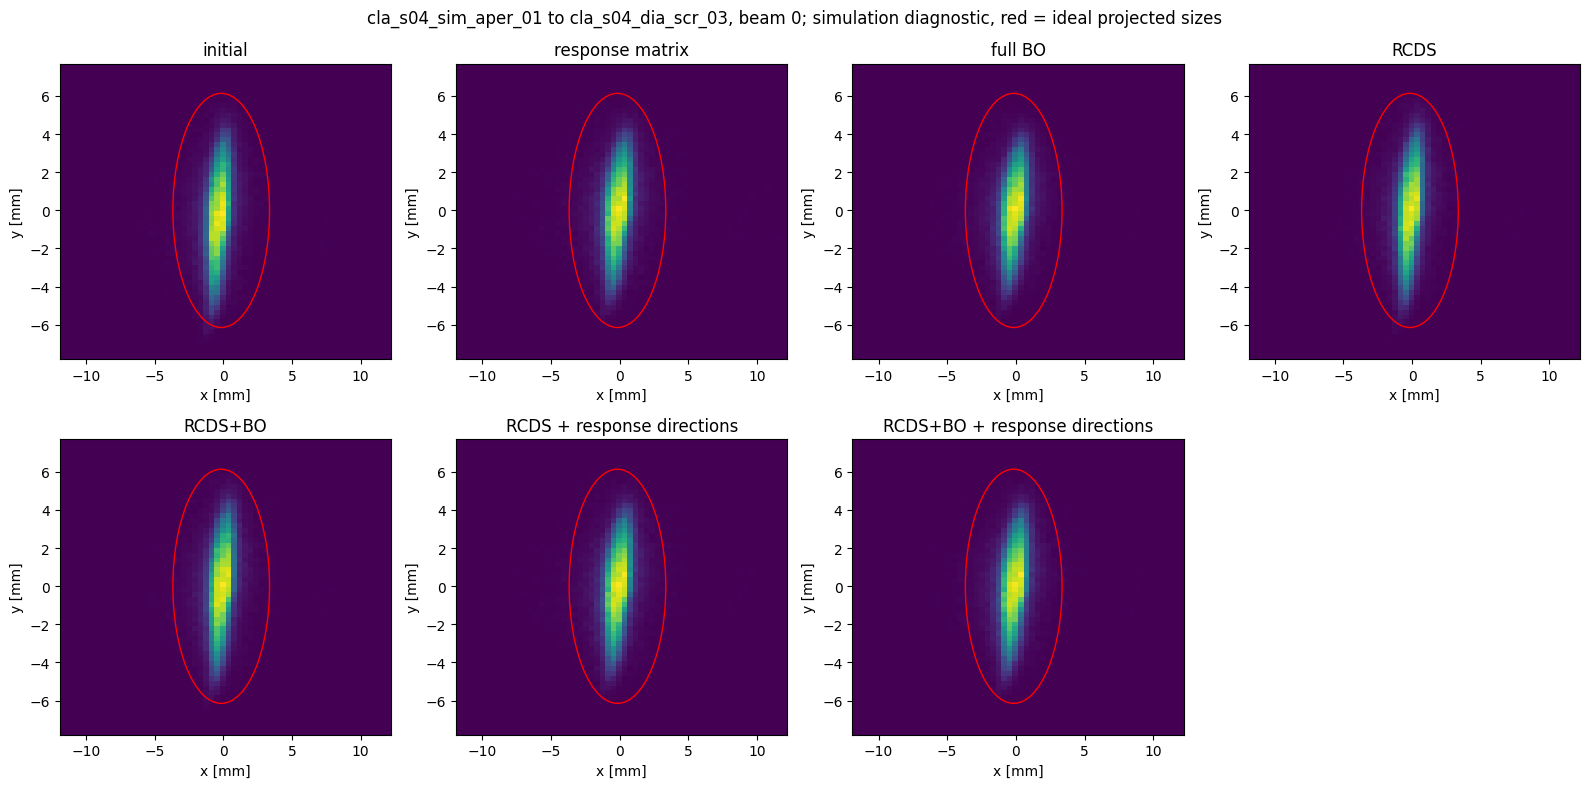

In [11]:
PLOT_BEAM_INDEX = 0
for name, item in section_models.items():
    beam = item["beams"][PLOT_BEAM_INDEX]
    machine = load_section_lattice()
    plan, model = item["plan"], item["model"]
    images = []
    for title, controls in [("initial", item["start"])] + [(method, selected_controls[name, PLOT_BEAM_INDEX, method]) for method in METHODS]:
        apply_knobs(machine, plan.knobs, controls)
        output = track_interval(machine, plan, beam)
        live = output.survival_probabilities.detach().cpu().numpy() > 0
        xy = output.particles.detach().cpu().numpy()[live][:, [0, 2]] * 1e3
        images.append((title, xy))
    from matplotlib.patches import Ellipse
    fig, axes = plt.subplots(2, 4, figsize=(16, 8), squeeze=False)
    # Shared spatial extent includes all surviving particles and the ideal 3-sigma ellipse.
    cloud = np.concatenate([xy for _, xy in images] + [np.array([model.target[:2]*1e3-3*model.target[2:]*1e3, model.target[:2]*1e3+3*model.target[2:]*1e3])])
    extent = [(cloud[:,j].min(), cloud[:,j].max()) for j in range(2)]
    for ax, (title, xy) in zip(axes.flat, images):
        ax.hist2d(xy[:,0], xy[:,1], bins=60, range=extent, cmap="viridis")
        ax.add_patch(Ellipse(model.target[:2]*1e3, 6*model.target[2]*1e3,
                             6*model.target[3]*1e3, fill=False, edgecolor="red", label="ideal 3 sigma"))
        ax.set(title=title, xlabel="x [mm]", ylabel="y [mm]")
    for ax in list(axes.flat)[len(images):]: ax.axis("off")
    fig.suptitle(f"{name}, beam {PLOT_BEAM_INDEX}; simulation diagnostic, red = ideal projected sizes")
    plt.tight_layout()


## 4. How to interpret this comparison

The response method repeatedly corrects the measured exit error with a damped ideal-model step. Its
failure mode is model error: it assumes the ideal input centre and covariance, a locally linear
section, and correct magnet calibration. The varied input beams deliberately violate the first
assumption.

Response directions have a weaker requirement. Even if the linear prediction is inaccurate, the
dominant right-singular vectors can still order RCDS searches along combinations that move the
measured output efficiently. Compare each direction-informed row only with the corresponding unit
direction row at the same budget.

A four-moment screen response has rank at most four. Sections with more than four controls
therefore contain response-null directions. The full SVD completes the basis, but those null
directions have no first-order evidence from one screen and may consume budget. A later experiment
can search only active modes first, then add null directions if the objective stalls.

This notebook does not use actual input-screen data and does not reconstruct angles. It also
models setting errors as a displaced normalized start rather than hidden calibration or alignment
errors. Those are deliberate boundaries for this isolated test.

## 5. RL workflow: simulation, one-beam adaptation, and transfer

The PPO experiment has three distinct phases for every selected section:

1. **Simulator pretraining.** Independent beams are sampled from the selected section beam source
   (the new correlated nominal distribution by default). Independent one-beam and several-beam policies have the same rollout budget,
   network initialization, and learning settings. These interactions are offline model calls.
2. **Machine adaptation on one beam.** A pretrained policy is copied and updated using repeated
   episodes on test beam 0. Each reset and action requires a final-screen image, so these calls are
   reported as machine adaptation measurements. This is a separate axis from the number of
   simulation training beams above.
3. **Frozen transfer.** Both the pretrained and adapted policies are frozen, then applied to beams
   1 onward without gradient updates. Only this held-out set enters the RL transfer table.

This notebook has no hardware connection, so phase 2 is an **emulated machine experiment** backed
by the same screen-measurement interface. The accounting and separation are ready for hardware,
but the result is not evidence of a real sim-to-real transfer. A hardware adapter must implement
reset/set-magnets/read-final-screen while preserving the normalized controls and safety limits.

### Physics-guided residual PPO

For full phase-space state z=(x, p_x, y, p_y, tau, p), ideal first-order propagation gives

mu_2 = M(u) mu_1 + d(u),                 Sigma_2 = M(u) Sigma_1 M(u)^T.

Use the full map in dispersive sections; a closed 4D transverse map needs negligible coupling
to longitudinal coordinates. The screen map keeps mu_x, mu_y, sqrt(Sigma_xx), and
sqrt(Sigma_yy). Differentiating that map
around the ideal beam and reference magnets gives the saved response J. For the measured scaled
residual r, a bounded ridge solve supplies a local physics correction

delta_u_phys = argmin ||J delta_u + r||^2 + alpha ||delta_u||^2.

The environment applies

a_applied = clip(a_PPO + lambda a_phys, -1, 1).

Thus PPO learns the residual left by the ideal model. RL_PHYSICS_WEIGHT=lambda controls the prior:
zero is ordinary PPO, while a positive value incorporates ideal propagation. This uses no actual
input-screen measurement and does not claim that the model is exact.

Simulation pretraining uses `RL_TRAIN_PARTICLES` (at most 4096 by default); adaptation and
held-out evaluation still use `NUM_PARTICLES`. This changes particle sampling accuracy, not the
transport physics. For a resolution-matched comparison set `RL_TRAIN_PARTICLES=NUM_PARTICLES`.
Apertures and losses remain active. `RL_FAST_TRACKING` omits nonblocking zero-length screen
copies because this environment reads exit particle moments, not camera images; blocking
screens remain in the transport. Results can differ slightly from floating-point map regrouping.
Iteration timing and ETA are printed during each training phase. PPO iterations, episodes,
horizon, and the four policy variants are unchanged.


All RL phases now use `load_section_lattice()` and the same `sample_section_input()` beam
construction as the classical comparison. The reduced-particle pretraining pool comes from the
new correlated nominal beam and is propagated to each section's entrance through the new optics
and apertures. Adaptation/evaluation retain NUM_PARTICLES. Physics priors use the matching nominal
response matrix; old-lattice checkpoints must not be reused. Saved artifacts record the lattice,
aperture setting and beam source, and are stored separately under `experiment_outputs/section_models`.


In [12]:
def sample_rl_beam(configuration, reference_lattice, seed):
    return sample_section_input(configuration, reference_lattice, seed,
                                RL_TRAIN_PARTICLES, SECTION_BEAM_SEVERITY)


def make_rl_environment(item, beam, physics_weight):
    lattice = load_section_lattice()
    plan = make_section_plan(
        lattice,
        item["configuration"]["input_screen"],
        item["configuration"]["output_screen"],
        include_rf_phase=False,
    )
    return SectionRLEnv(
        lattice,
        plan,
        beam,
        item["model"],
        item["start"],
        config=SectionRLConfig(
            horizon=RL_HORIZON,
            max_knob_step=RL_MAX_KNOB_STEP,
            physics_weight=physics_weight,
            noise_fraction=READOUT_NOISE,
            ridge=RESPONSE_RIDGE,
            fast_tracking=RL_FAST_TRACKING,
        ),
    )


def training_progress(label, iterations):
    def report(row):
        i = row["iteration"]
        if i == 1 or i % RL_PROGRESS_EVERY == 0 or i == iterations:
            elapsed = row["elapsed_seconds"]
            eta = elapsed / i * (iterations - i)
            print(f"{label}: {i}/{iterations}, elapsed {elapsed/60:.1f} min, "
                  f"ETA {eta/60:.1f} min, best {row['mean_best_loss']:.4g}", flush=True)
    return report

print({"pretraining particles": RL_TRAIN_PARTICLES, "adaptation/evaluation particles": NUM_PARTICLES,
       "pretraining images per variant": RL_PRETRAIN_ITERATIONS * RL_PRETRAIN_EPISODES * (RL_HORIZON+1),
       "fast moment tracking": RL_FAST_TRACKING})

pretrain_config = PPOConfig(
    iterations=RL_PRETRAIN_ITERATIONS,
    episodes_per_iteration=RL_PRETRAIN_EPISODES,
    horizon=RL_HORIZON,
    max_knob_step=RL_MAX_KNOB_STEP,
    learning_rate=3e-4,
    update_epochs=3 if FAST_RUN else 5,
    minibatch_size=32,
    reward_scale=0.25,
)
adapt_config = PPOConfig(
    iterations=RL_ADAPT_ITERATIONS,
    episodes_per_iteration=RL_ADAPT_EPISODES,
    horizon=RL_HORIZON,
    max_knob_step=RL_MAX_KNOB_STEP,
    learning_rate=1e-4,
    update_epochs=3,
    minibatch_size=32,
    entropy_weight=0.002,
    reward_scale=0.25,
)

RL_VARIANTS = {
    "PPO / one beam": (0.0, 1),
    "PPO / several beams": (0.0, RL_SIMULATION_BEAMS),
    "physics PPO / one beam": (RL_PHYSICS_WEIGHT, 1),
    "physics PPO / several beams": (RL_PHYSICS_WEIGHT, RL_SIMULATION_BEAMS),
}
rl_artifacts = {}
training_rows = []

for section_index, (section_name, item) in enumerate(section_models.items()):
    reference_lattice = load_section_lattice()
    simulator_beams = [
        sample_rl_beam(
            item["configuration"],
            reference_lattice,
            SEED + 10_000 + 100 * section_index + index,
        )
        for index in range(RL_SIMULATION_BEAMS)
    ]
    for variant, (physics_weight, training_beam_count) in RL_VARIANTS.items():
        training_environments = [
            make_rl_environment(item, beam, physics_weight)
            for beam in simulator_beams[:training_beam_count]
        ]
        initialization_seed = SEED + 20_000 + section_index
        torch.manual_seed(initialization_seed)
        agent = ActorCritic(
            training_environments[0].observation_dim,
            training_environments[0].action_dim,
            hidden=RL_HIDDEN,
        )
        pretrain_history = train_ppo(
            agent,
            training_environments,
            pretrain_config,
            seed=SEED + 30_000 + section_index,
            progress=training_progress(f"{section_name} / {variant} / pretrain", pretrain_config.iterations),
        )
        pretrained = deepcopy(agent).eval()
        pretrained.requires_grad_(False)

        # Beam 0 is the only beam used for machine adaptation.
        adapted = deepcopy(pretrained).requires_grad_(True)
        adaptation_environment = make_rl_environment(
            item,
            item["beams"][0],
            physics_weight,
        )
        adapt_history = train_ppo(
            adapted,
            adaptation_environment,
            adapt_config,
            seed=SEED + 40_000 + section_index,
            progress=training_progress(f"{section_name} / {variant} / adapt", adapt_config.iterations),
        )
        adapted.eval().requires_grad_(False)

        safe_name = re.sub(r"[^a-z0-9]+", "_", section_name.lower()).strip("_")
        safe_variant = re.sub(r"[^a-z0-9]+", "_", variant.lower()).strip("_")
        checkpoint = OUTPUT_DIR / f"{safe_name}_{safe_variant}_adapted.pt"
        torch.save({
            "state_dict": adapted.state_dict(),
            "lattice_model": SECTION_MODEL,
            "detailed_apertures": SECTION_DETAILED_APERTURES if SECTION_MODEL != "scorer" else False,
            "beam_source": item["configuration"]["beam_source"],
            "beam_severity": SECTION_BEAM_SEVERITY,
            "observation_dim": adapted.observation_dim,
            "action_dim": adapted.action_dim,
            "hidden": RL_HIDDEN,
            "input_screen": item["configuration"]["input_screen"],
            "output_screen": item["configuration"]["output_screen"],
            "physics_weight": physics_weight,
            "training_beam_count": training_beam_count,
            "pretrain_particles": RL_TRAIN_PARTICLES,
            "evaluation_particles": NUM_PARTICLES,
            "fast_moment_tracking": RL_FAST_TRACKING,
            "knob_labels": [k.label for k in item["plan"].knobs],
            "knob_lower": [k.lower for k in item["plan"].knobs],
            "knob_upper": [k.upper for k in item["plan"].knobs],
            "target": item["model"].target.tolist(),
            "scale": item["model"].scale.tolist(),
            "response": item["model"].response.tolist(),
            "start": item["start"].tolist(),
            "max_knob_step": RL_MAX_KNOB_STEP,
            "horizon": RL_HORIZON,
            "readout_noise": READOUT_NOISE,
            "ridge": RESPONSE_RIDGE,
        }, checkpoint)

        rl_artifacts[section_name, variant] = dict(
            pretrained=pretrained,
            adapted=adapted,
            physics_weight=physics_weight,
            pretrain_history=pd.DataFrame(pretrain_history),
            adapt_history=pd.DataFrame(adapt_history),
            pretrain_measurements=pretrain_history[-1]["offline_measurements"],
            adaptation_measurements=adapt_history[-1]["offline_measurements"],
            checkpoint=checkpoint,
        )
        training_rows.append(dict(
            section=section_name,
            variant=variant,
            simulator_beams=training_beam_count,
            simulator_pretraining_calls=pretrain_history[-1]["offline_measurements"],
            one_beam_adaptation_calls=adapt_history[-1]["offline_measurements"],
            deployment_calls_per_beam=RL_HORIZON + 1,
            physics_weight=physics_weight,
            checkpoint=checkpoint.name,
        ))

training_accounting = pd.DataFrame(training_rows)
assert training_accounting.simulator_pretraining_calls.nunique() == 1
assert training_accounting.one_beam_adaptation_calls.nunique() == 1
display(training_accounting)

{'pretraining particles': 4096, 'adaptation/evaluation particles': 100000, 'pretraining images per variant': 18432, 'fast moment tracking': True}
cla_s04_sim_aper_01 to cla_s04_dia_scr_03 / PPO / one beam / pretrain: 1/128, elapsed 0.0 min, ETA 3.5 min, best 1.165
cla_s04_sim_aper_01 to cla_s04_dia_scr_03 / PPO / one beam / pretrain: 8/128, elapsed 0.2 min, ETA 3.4 min, best 0.6698
cla_s04_sim_aper_01 to cla_s04_dia_scr_03 / PPO / one beam / pretrain: 16/128, elapsed 0.4 min, ETA 3.1 min, best 0.6053
cla_s04_sim_aper_01 to cla_s04_dia_scr_03 / PPO / one beam / pretrain: 24/128, elapsed 0.7 min, ETA 2.9 min, best 0.5644
cla_s04_sim_aper_01 to cla_s04_dia_scr_03 / PPO / one beam / pretrain: 32/128, elapsed 0.9 min, ETA 2.7 min, best 0.4709
cla_s04_sim_aper_01 to cla_s04_dia_scr_03 / PPO / one beam / pretrain: 40/128, elapsed 1.1 min, ETA 2.5 min, best 0.3965
cla_s04_sim_aper_01 to cla_s04_dia_scr_03 / PPO / one beam / pretrain: 48/128, elapsed 1.4 min, ETA 2.3 min, best 0.4273
cla_s04_si

,section,variant,simulator_beams,simulator_pretraining_calls,one_beam_adaptation_calls,deployment_calls_per_beam,physics_weight,checkpoint
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / one beam,1,18432,72,9,0.0,cla_s04_sim_aper_01_to_cla_s04_dia_scr_03_ppo_...
1,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / several beams,4,18432,72,9,0.0,cla_s04_sim_aper_01_to_cla_s04_dia_scr_03_ppo_...
2,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / one beam,1,18432,72,9,0.7,cla_s04_sim_aper_01_to_cla_s04_dia_scr_03_phys...
3,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / several beams,4,18432,72,9,0.7,cla_s04_sim_aper_01_to_cla_s04_dia_scr_03_phys...


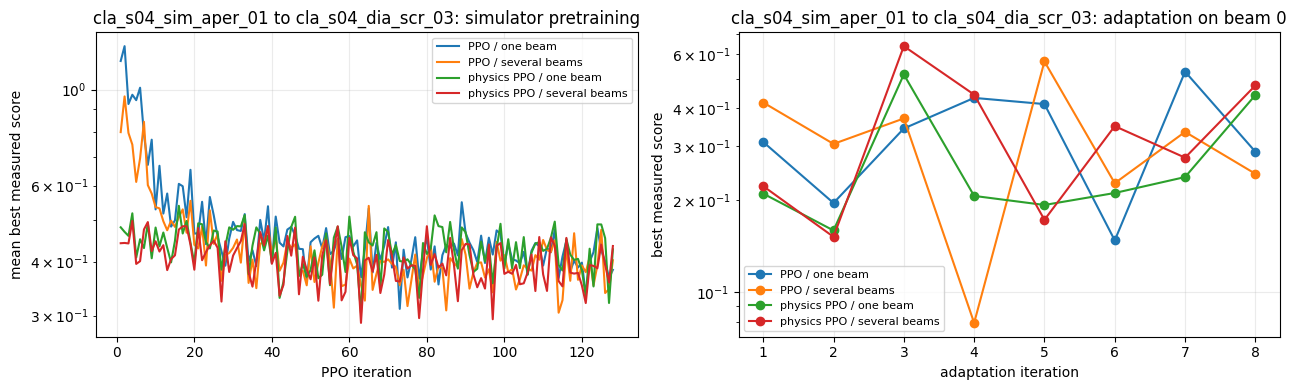

In [13]:
fig, axes = plt.subplots(
    len(section_models), 2,
    figsize=(13, 4 * len(section_models)),
    squeeze=False,
)
for row_index, section_name in enumerate(section_models):
    for variant in RL_VARIANTS:
        artifact = rl_artifacts[section_name, variant]
        pretrain = artifact["pretrain_history"]
        adaptation = artifact["adapt_history"]
        axes[row_index, 0].plot(
            pretrain.iteration,
            pretrain.mean_best_loss,
            label=variant,
        )
        axes[row_index, 1].plot(
            adaptation.iteration,
            adaptation.mean_best_loss,
            "o-",
            label=variant,
        )
    axes[row_index, 0].set(
        title=f"{section_name}: simulator pretraining",
        xlabel="PPO iteration",
        ylabel="mean best measured score",
        yscale="log",
    )
    axes[row_index, 1].set(
        title=f"{section_name}: adaptation on beam 0",
        xlabel="adaptation iteration",
        ylabel="best measured score",
        yscale="log",
    )
    for axis in axes[row_index]:
        axis.grid(alpha=.25)
        axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Freeze policies and correct different beams

The deployment beams were not used for simulator training or machine adaptation.
Test beam 0 is reserved for adaptation and excluded from every combined comparison. Each policy gets
one reset image and RL_HORIZON action images. Selection uses the best noisy measured setting;
the clean score below is calculated afterward only for simulation diagnosis.

The sim-only rows show the reusable pretrained policy. The adapted rows show whether measurements
from beam 0 improve or overfit transfer to beams 1 onward.

In [14]:
rl_rows, rl_sessions = [], {}
for section_name, item in section_models.items():
    for beam_index in range(1, N_BEAMS):
        beam = item["beams"][beam_index]
        for variant, (physics_weight, _) in RL_VARIANTS.items():
            artifact = rl_artifacts[section_name, variant]
            for phase, policy in (
                ("sim-only", artifact["pretrained"]),
                ("sim + one-beam adaptation", artifact["adapted"]),
            ):
                environment = make_rl_environment(item, beam, physics_weight)
                apply_knobs(
                    environment.lattice,
                    environment.plan.knobs,
                    item["start"],
                )
                initial_truth = section_readout(track_interval(
                    environment.lattice,
                    environment.plan,
                    beam,
                ))[0]
                selected, session = run_section_policy(
                    policy,
                    environment,
                    seed=SEED + 50_000 + 100 * beam_index,
                )
                apply_knobs(environment.lattice, environment.plan.knobs, selected)
                output = track_interval(environment.lattice, environment.plan, beam)
                final_truth = section_readout(output)[0]
                method = f"{variant} ({phase})"
                rl_rows.append(dict(
                    section=section_name,
                    beam=beam_index,
                    method=method,
                    **optics_diagnostics(output, item),
                    online_measurements=len(session.records),
                    initial_truth=section_value(initial_truth, item["model"]),
                    best_observed=session.best()["value"],
                    final_truth=section_value(final_truth, item["model"]),
                    orbit_truth=section_value(final_truth, item["model"], "orbit"),
                    shape_truth=section_value(final_truth, item["model"], "shape"),
                    improved=(
                        section_value(final_truth, item["model"])
                        < section_value(initial_truth, item["model"])
                    ),
                    simulator_pretraining_calls=artifact["pretrain_measurements"],
                    one_beam_adaptation_calls=(
                        artifact["adaptation_measurements"]
                        if phase == "sim + one-beam adaptation"
                        else 0
                    ),
                    physics_weight=physics_weight,
                ))
                rl_sessions[section_name, beam_index, method] = session

rl_results = pd.DataFrame(rl_rows)
assert (rl_results.online_measurements == RL_HORIZON + 1).all()
assert (rl_results.beam > 0).all()
display(rl_results)

,section,beam,method,covariance_error,angle_error_urad,survival,online_measurements,initial_truth,best_observed,final_truth,orbit_truth,shape_truth,improved,simulator_pretraining_calls,one_beam_adaptation_calls,physics_weight
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,PPO / one beam (sim-only),3.248799,89.932063,0.99168,9,0.938416,0.208173,0.208173,0.055834,0.360512,True,18432,0,0.0
1,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,PPO / one beam (sim + one-beam adaptation),2.706174,92.880907,0.99168,9,0.938416,0.181266,0.181266,0.041813,0.320719,True,18432,72,0.0
2,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,PPO / several beams (sim-only),1.662742,150.390421,0.99168,9,0.938416,0.129712,0.129712,0.058074,0.201351,True,18432,0,0.0
3,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,PPO / several beams (sim + one-beam adaptation),0.868035,88.626167,0.99168,9,0.938416,0.106588,0.106588,0.085337,0.127838,True,18432,72,0.0
4,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,physics PPO / one beam (sim-only),0.735852,106.772438,0.99168,9,0.938416,0.111204,0.111204,0.046039,0.176369,True,18432,0,0.7
5,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,physics PPO / one beam (sim + one-beam adaptat...,0.710779,101.970894,0.99168,9,0.938416,0.106238,0.106238,0.036771,0.175706,True,18432,72,0.7
6,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,physics PPO / several beams (sim-only),0.798620,61.565713,0.99168,9,0.938416,0.259914,0.259914,0.417374,0.102454,True,18432,0,0.7
7,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,1,physics PPO / several beams (sim + one-beam ad...,0.139903,142.299061,0.99168,9,0.938416,0.332909,0.332909,0.575789,0.090028,True,18432,72,0.7
8,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,2,PPO / one beam (sim-only),3.207986,123.233919,0.99074,9,1.547060,0.213896,0.213896,0.087608,0.340184,True,18432,0,0.0
9,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,2,PPO / one beam (sim + one-beam adaptation),2.663512,120.203250,0.99074,9,1.547060,0.157197,0.157197,0.015238,0.299155,True,18432,72,0.0


In [15]:
rl_summary = rl_results.groupby(["section", "method"], sort=False).agg(
    mean_initial=("initial_truth", "mean"),
    mean_final=("final_truth", "mean"),
    worst_final=("final_truth", "max"),
    mean_orbit=("orbit_truth", "mean"),
    mean_shape=("shape_truth", "mean"),
    improvement_rate=("improved", "mean"),
    deployment_calls=("online_measurements", "mean"),
    simulator_pretraining_calls=("simulator_pretraining_calls", "first"),
    one_beam_adaptation_calls=("one_beam_adaptation_calls", "first"),
).reset_index()
rl_summary["mean_reduction_percent"] = 100 * (
    1 - rl_summary.mean_final / rl_summary.mean_initial
)
display(rl_summary.sort_values(["section", "mean_final"]))

# Compare against the earlier methods on exactly the same held-out beams.
classic_transfer = results[
    (results.beam > 0)
    & results.method.isin([
        "response matrix",
        "full BO",
        "RCDS",
        "RCDS+BO",
        "RCDS + response directions",
        "RCDS+BO + response directions",
    ])
].copy()
classic_transfer["simulator_pretraining_calls"] = 0
classic_transfer["one_beam_adaptation_calls"] = 0

combined_transfer = pd.concat(
    [classic_transfer, rl_results],
    ignore_index=True,
    sort=False,
)
combined_summary = combined_transfer.groupby(
    ["section", "method"], sort=False
).agg(
    mean_final=("final_truth", "mean"),
    worst_final=("final_truth", "max"),
    improvement_rate=("improved", "mean"),
    deployment_calls=("online_measurements", "mean"),
    simulator_pretraining_calls=("simulator_pretraining_calls", "first"),
    one_beam_adaptation_calls=("one_beam_adaptation_calls", "first"),
).reset_index()
combined_summary["rank"] = combined_summary.groupby("section").mean_final.rank()
display(combined_summary.sort_values(["section", "rank"]))

,section,method,mean_initial,mean_final,worst_final,mean_orbit,mean_shape,improvement_rate,deployment_calls,simulator_pretraining_calls,one_beam_adaptation_calls,mean_reduction_percent
3,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / several beams (sim + one-beam adaptation),1.463157,0.120354,0.129262,0.131752,0.108957,1.0,9.0,18432,72,91.774339
5,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / one beam (sim + one-beam adaptat...,1.463157,0.123858,0.166577,0.089904,0.157811,1.0,9.0,18432,72,91.534905
2,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / several beams (sim-only),1.463157,0.137506,0.172431,0.128829,0.146183,1.0,9.0,18432,0,90.602107
4,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / one beam (sim-only),1.463157,0.146129,0.196537,0.123230,0.169028,1.0,9.0,18432,0,90.012761
1,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / one beam (sim + one-beam adaptation),1.463157,0.189379,0.229674,0.055735,0.323023,1.0,9.0,18432,72,87.056824
6,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / several beams (sim-only),1.463157,0.220382,0.289195,0.341823,0.098941,1.0,9.0,18432,0,84.937912
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / one beam (sim-only),1.463157,0.231470,0.272341,0.125685,0.337255,1.0,9.0,18432,0,84.180092
7,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / several beams (sim + one-beam ad...,1.463157,0.326843,0.373460,0.544658,0.109028,1.0,9.0,18432,72,77.661790


,section,method,mean_final,worst_final,improvement_rate,deployment_calls,simulator_pretraining_calls,one_beam_adaptation_calls,rank
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,response matrix,0.003387,0.010153,1.0,128.0,0,0,1.0
4,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS + response directions,0.013737,0.018141,1.0,128.0,0,0,2.0
2,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS,0.020824,0.041242,1.0,128.0,0,0,3.0
3,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS+BO,0.036267,0.045515,1.0,128.0,0,0,4.0
5,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS+BO + response directions,0.041603,0.045635,1.0,128.0,0,0,5.0
1,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,full BO,0.118047,0.146866,1.0,128.0,0,0,6.0
9,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / several beams (sim + one-beam adaptation),0.120354,0.129262,1.0,9.0,18432,72,7.0
11,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / one beam (sim + one-beam adaptat...,0.123858,0.166577,1.0,9.0,18432,72,8.0
8,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / several beams (sim-only),0.137506,0.172431,1.0,9.0,18432,0,9.0
10,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / one beam (sim-only),0.146129,0.196537,1.0,9.0,18432,0,10.0


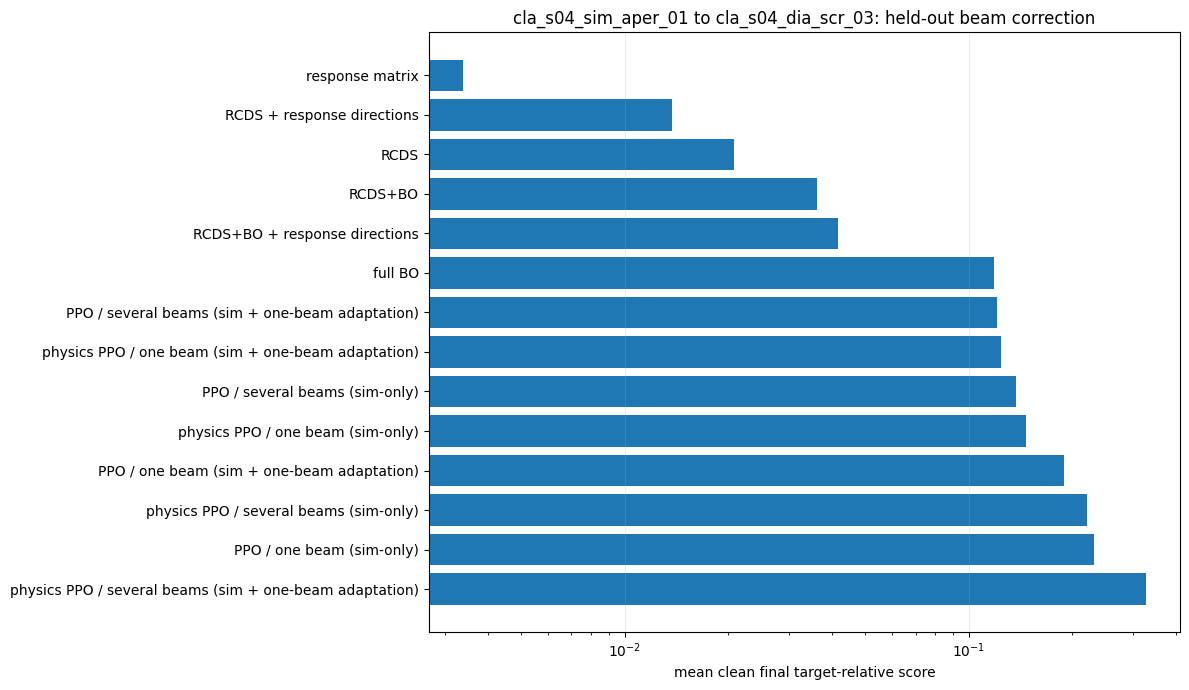


cla_s04_sim_aper_01 to cla_s04_dia_scr_03
  One-beam adaptation improves held-out PPO / one beam by 18.2% (0.2315 -> 0.1894).
  One-beam adaptation improves held-out PPO / several beams by 12.5% (0.1375 -> 0.1204).
  One-beam adaptation improves held-out physics PPO / one beam by 15.2% (0.1461 -> 0.1239).
  One-beam adaptation degrades held-out physics PPO / several beams by 48.3% (0.2204 -> 0.3268).
  Physics prior, one beam: 0.1894 -> 0.1239 (lower is better).
  Physics prior, several beams: 0.1204 -> 0.3268 (lower is better).


In [16]:
fig, axes = plt.subplots(
    len(section_models), 1,
    figsize=(12, 7 * len(section_models)),
    squeeze=False,
)
for axis, section_name in zip(axes[:, 0], section_models):
    rows = combined_summary[combined_summary.section == section_name].sort_values("mean_final")
    axis.barh(rows.method, rows.mean_final)
    axis.invert_yaxis()
    axis.set(
        title=f"{section_name}: held-out beam correction",
        xlabel="mean clean final target-relative score",
        xscale="log",
    )
    axis.grid(alpha=.25, axis="x")
plt.tight_layout()
plt.show()

for section_name in section_models:
    table = rl_summary[rl_summary.section == section_name].set_index("method")
    print(f"\n{section_name}")
    for variant in RL_VARIANTS:
        before = table.loc[f"{variant} (sim-only)", "mean_final"]
        after = table.loc[
            f"{variant} (sim + one-beam adaptation)",
            "mean_final",
        ]
        effect = 100 * (after / before - 1)
        word = "improves" if effect < 0 else "degrades"
        print(
            f"  One-beam adaptation {word} held-out {variant} by "
            f"{abs(effect):.1f}% ({before:.4g} -> {after:.4g})."
        )
    for training in ("one beam", "several beams"):
        vanilla = table.loc[f"PPO / {training} (sim + one-beam adaptation)", "mean_final"]
        informed = table.loc[f"physics PPO / {training} (sim + one-beam adaptation)", "mean_final"]
        print(f"  Physics prior, {training}: {vanilla:.4g} -> {informed:.4g} (lower is better).")

## 7. What the RL result means

The policy is section-specific: changing the screen pair can change the number and identity of
knobs, so the notebook trains a separate actor for each section. It observes current normalized
knobs, the four scaled final-screen residuals, current objective, remaining episode fraction,
and a valid-reading flag. Physics weight zero skips the response solver entirely.
It never observes the true input covariance, divergences, or clean simulation state.

Physics can enter RL at several levels. This experiment uses an action prior because it remains
usable when the input beam is unknown and its weight has a clear zero limit. Other valid choices
are response features in the observation, imitation pretraining on response corrections, or an
auxiliary consistency loss comparing measured transitions with r_next=r+J delta_u. An auxiliary
loss should be down-weighted when model error is large; otherwise it can force the policy to
reproduce the same bias that adaptation is meant to remove.

Judge sim-to-machine adaptation by held-out performance and by its explicit measurement cost.
Improvement on beam 0 alone is insufficient. If adaptation degrades beams 1 onward, it has
specialized to one input beam; reduce the learning rate or iterations, regularize toward the
pretrained weights, or adapt on several representative beams. The emulated result should be
repeated with calibration errors, misalignments, time drift, camera noise, and hardware limits
before choosing a real-machine measurement budget.

## 8. Equal deployment budget and full-optics diagnostics

The preceding table retains each method's configured budget: response uses RESPONSE_STEPS+1 images,
classical search uses MEASUREMENT_BUDGET, and PPO uses RL_HORIZON+1. Its rank alone is not a fair speed
comparison. This table uses the first RL_HORIZON+1 measured points from each classical search,
selects the best by the **noisy** objective, and reports the cached clean value at that point.
No additional measurement or retraining is performed. Response uses the same maximum budget
by default; reducing RESPONSE_STEPS can use fewer images.

The local objective is mean absolute scaled error in (mu_x, mu_y, sigma_x, sigma_y). Missing images
receive a finite failure value and are never preferred to valid images. Readout noise is controlled
by READOUT_NOISE; the idealized screen uses all surviving particles and has no
finite camera field of view. This is deliberately separate from score.py's FEH camera metric.

The final diagnostic table reports angle error and all 16 transverse covariance entries relative
to the propagated ideal beam, using simulator truth only. A good spot-size score can coexist with
a large covariance error. Full optics matching would require additional measurements, such as
quadrupole scans or several transport views; actual input angles/covariance are not supplied here.

All policies currently train and deploy from the same section start setting. This tests transfer
between input beams, not transfer between arbitrary starting magnet configurations. Machine
adaptation remains simulated. Results from four held-out beams and one training seed are exploratory.

In [17]:
matched_rows = []
for section_name, item in section_models.items():
    for beam_index in range(1, N_BEAMS):
        for method in METHODS:
            records = sessions[section_name, beam_index, method].records[:RL_HORIZON + 1]
            selected = min(records, key=lambda record: record["value"])
            matched_rows.append(dict(
                section=section_name, beam=beam_index, method=method,
                final_truth=section_value(selected["clean"], item["model"]),
                online_measurements=len(records),
            ))
matched_results = pd.concat([pd.DataFrame(matched_rows), rl_results], ignore_index=True)
matched_summary = matched_results.groupby(["section", "method"]).agg(
    mean_final=("final_truth", "mean"), worst_final=("final_truth", "max"),
    deployment_calls=("online_measurements", "mean"),
).reset_index()
print("Matched maximum deployment budget; actual calls shown for every method:")
display(matched_summary.sort_values(["section", "mean_final"]))

print("Full configured budgets: simulation-only optics diagnostics (held-out beams):")
optics_summary = combined_transfer.groupby(["section", "method"]).agg(
    screen_score=("final_truth", "mean"),
    covariance_error=("covariance_error", "mean"),
    angle_error_urad=("angle_error_urad", "mean"),
    minimum_survival=("survival", "min"),
).reset_index()
display(optics_summary)
# These are diagnostics, never targets supplied to a tuner.
matched_results.to_csv(OUTPUT_DIR / "section_matched_budget_results.csv", index=False)
combined_transfer.to_csv(OUTPUT_DIR / "section_comparison_results.csv", index=False)
training_accounting.to_csv(OUTPUT_DIR / "section_training_accounting.csv", index=False)

Matched maximum deployment budget; actual calls shown for every method:


,section,method,mean_final,worst_final,deployment_calls
2,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / several beams (sim + one-beam adaptation),0.120354,0.129262,9.0
9,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / one beam (sim + one-beam adaptat...,0.123858,0.166577,9.0
3,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / several beams (sim-only),0.137506,0.172431,9.0
10,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / one beam (sim-only),0.146129,0.196537,9.0
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / one beam (sim + one-beam adaptation),0.189379,0.229674,9.0
12,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / several beams (sim-only),0.220382,0.289195,9.0
1,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / one beam (sim-only),0.231470,0.272341,9.0
11,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / several beams (sim + one-beam ad...,0.326843,0.373460,9.0
4,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS,0.489001,0.916028,9.0
5,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS + response directions,0.598797,0.898523,9.0


Full configured budgets: simulation-only optics diagnostics (held-out beams):


,section,method,screen_score,covariance_error,angle_error_urad,minimum_survival
0,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / one beam (sim + one-beam adaptation),0.189379,2.874247,123.268106,0.99031
1,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / one beam (sim-only),0.231470,3.028587,115.458627,0.99031
2,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / several beams (sim + one-beam adaptation),0.120354,0.848725,110.134453,0.99031
3,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,PPO / several beams (sim-only),0.137506,1.270894,141.474079,0.99031
4,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS,0.020824,0.293620,59.219238,0.99031
5,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS + response directions,0.013737,0.180058,127.317591,0.99031
6,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS+BO,0.036267,0.304456,58.500503,0.99031
7,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,RCDS+BO + response directions,0.041603,0.283957,61.008250,0.99031
8,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,full BO,0.118047,0.871442,251.539714,0.99031
9,cla_s04_sim_aper_01 to cla_s04_dia_scr_03,physics PPO / one beam (sim + one-beam adaptat...,0.123858,1.033844,97.794593,0.99031


## 9. Correct one machine screen by screen with a selected method

This cell can run after setup without completing PPO training. By default it loads the new
correlated nominal S02 beam, uses its unperturbed version for the model, and adds explicit
injection jitter for the unknown beam. The old scorer distribution remains selectable.
A single perturbed lattice is retained throughout. For each physical screen,
choose the nearest earlier screen with at least four quadrupole strengths and four corrector
angles in between. If that is impossible, use all controls from the S02 entrance and flag the
shortage. Windows may overlap and have more than eight controls. No RF controls are changed.

The actual input at each window is recomputed from the same root beam through the currently
corrected upstream machine. It is simulator state, not information given to the tuner. Targets
and response matrices always come from the ideal reference. Each measurement reads only the
selected exit screen; internal particle transport and clean audit plots are simulation diagnostics.
The model uses ideal moment readouts, not finite camera images or the official FEH score.

After each correction, magnets remain set for the next screen. Later overlapping corrections
can spoil earlier screens, so the final audit reevaluates **every** screen using the final lattice.
This is a single forward pass, not a guarantee of simultaneous full-optics correction. It finally
propagates to the end of the lattice even if correction was limited to the first few screens.
Choose any classical method in `FULL_METHOD`; existing PPO policies have section-specific inputs
and cannot be applied to new screen windows without training a matching policy.


Some downstream screens may have no valid ideal target because the nominal scorer beam is lost
in the reference lattice. These intervals are explicitly marked skipped; no objective or successful
correction is fabricated. If only the finite-difference scan loses the beam, the response scan
retries with smaller steps. The final audit reports actual survival even for skipped targets.


`FULL_VERBOSE` prints section starts, measurement progress every `FULL_LOG_EVERY` images,
skipped sections, section summaries, and the final audit. Reports distinguish **exit transmission**
(surviving particle weight relative to the original input beam) from **within-section transmission**
(exit weight divided by that window's incoming weight). Zero incoming weight gives an undefined
ratio (NaN), not 100% transmission. These are simulator diagnostics; no extra online images are
charged for reports. The first report describes each correction when it happened; the final audit
reflects all later overlapping changes. Percent columns are saved with the reports as CSV files.


**New nominal model, beam and apertures**

The final workflow now defaults to the **lattice-file strengths** recommended by
`nominal_model/README.md`, loaded directly rather than overwritten with the scorer's reference
tune. `FULL_MODEL="gpsr"` selects `nominal_model/CLARA_cheetah_S07_GPSR.json`: those are the scan
settings used when reconstructing the input beam, not the default correction optics.
`FULL_MODEL="scorer"` retains the old scorer loader and its case-state behavior.
The earlier isolated-section/RL comparisons are unchanged.

`nominal_model/initial_distribution.npz` contains 200,000 correlated 6D particles at
`cla_s02_sim_aper_01`, 35.8055 MeV, in Cheetah coordinates. We subsample those particles,
preserving correlations; there is no tau sign conversion. The stored beam is distinct from
`score.sample_beam`. The plant uses an explicitly documented affine injection-jitter model.
The NPZ has no charge, so the loader assumes 250 pC; charge does not affect this local objective.

`data/clara/lattice_data/apertures.json` supplies the new vacuum chambers: e.g. 17 mm pipe,
10 mm linacs, 4.1195 mm L4H and 5 mm TDC half apertures. The lattice JSON alone does not
insert these chambers. The work-local Cheetah loader mirrors the nominal-model aperture
placement without requiring xsuite, checks chamber changes and element exits, and overlays
those actual checks on the envelope plots. The scorer still inserts its own 50 mm pipes;
`score.py` is not modified. `FULL_MODEL_END` defaults to the nominal model's validated FEH readout.
This is Cheetah transport, not the more chromatic xsuite transport used to reconstruct the beam.

`load_full_lattice(errors=False)` builds the reference. `errors=True` adds seeded corrector/quad
setting errors and scorer-scale magnet/screen misalignments to a separate instance. It never
perturbs the response-model lattice. Screen offsets do not change the current moment-based
readout, which observes propagated beam moments rather than camera coordinates.

Every optimizer restores `session.best()["u"]` before propagation to the next window.
`selected_evaluation` and the red convergence marker show the chosen image, which can precede
the last one. Reported clean objectives and simulated transmission never select the setting.
Exit plots show the design ellipse in physical units and a design circle in normalized units;
a round overlay in millimetres would misrepresent an anisotropic target.


In [18]:
METHODS

('response matrix',
 'full BO',
 'RCDS',
 'RCDS+BO',
 'RCDS + response directions',
 'RCDS+BO + response directions')

In [19]:
MEASUREMENT_BUDGET

128

{'model': 'nominal', 'input beam': 'cla_s02_sim_aper_01', 'detailed apertures': True, 'misalignment severity': 1.0}


,input_screen,output_screen,quadrupoles,corrector_angles,enough_controls
0,cla_s02_sim_aper_01,cla_s02_dia_scr_01,2,2,False
1,cla_s02_sim_aper_01,cla_s02_dia_scr_02,2,6,False
2,cla_s02_sim_aper_01,cla_s02_dia_scr_03,5,6,True
3,cla_s02_dia_scr_02,cla_s03_dia_scr_01,4,4,True
4,cla_s02_dia_scr_02,cla_s04_dia_scr_01,6,6,True
5,cla_s03_dia_scr_01,cla_s04_dia_scr_02,4,4,True
6,cla_s03_dia_scr_01,cla_s04_dia_scr_03,4,4,True
7,cla_s03_dia_scr_01,cla_s04_dia_scr_04,4,6,True
8,cla_s03_dia_scr_01,cla_s04_dia_scr_05,4,6,True
9,cla_s04_dia_scr_05,cla_s05_dia_scr_01,5,6,True


Full correction: response matrix; 23 sections; up to 256 images per section
[1/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_01: 4 knobs; building ideal response
  [1/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_01: image 1/256, objective 0.5187, best measured 0.5187, exit transmission 100.0%
  [1/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_01: image 16/256, objective 0.1099, best measured 0.1099, exit transmission 100.0%
  [1/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_01: image 32/256, objective 0.02738, best measured 0.02738, exit transmission 100.0%
  [1/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_01: image 48/256, objective 0.01237, best measured 0.01237, exit transmission 100.0%
  [1/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_01: image 64/256, objective 0.009688, best measured 0.009688, exit transmission 100.0%
  [1/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_01: image 80/256, objective 0.009215, best measured 0.009215, exit transmission 100.0%
  [1/23] cla_s02_sim_aper_01 -> cla_s02_dia_

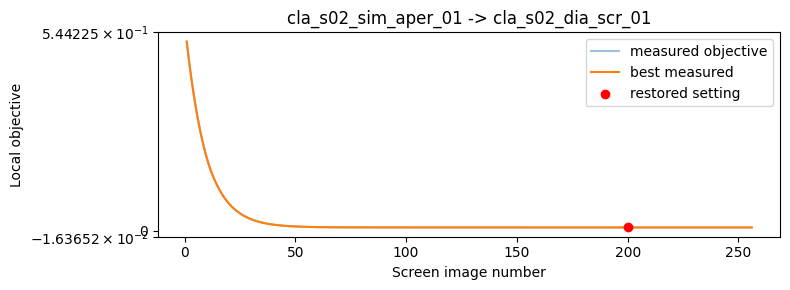

[2/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_02: 8 knobs; building ideal response
  [2/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_02: image 1/256, objective 0.6985, best measured 0.6985, exit transmission 100.0%
  [2/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_02: image 16/256, objective 0.1253, best measured 0.1253, exit transmission 100.0%
  [2/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_02: image 32/256, objective 0.02163, best measured 0.02163, exit transmission 100.0%
  [2/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_02: image 48/256, objective 0.003803, best measured 0.003803, exit transmission 100.0%
  [2/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_02: image 64/256, objective 0.0007294, best measured 0.0007294, exit transmission 100.0%
  [2/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_02: image 80/256, objective 0.0001459, best measured 0.0001459, exit transmission 100.0%
  [2/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_02: image 96/256, objective 2.902e-05, best measured 2.902e-05, ex

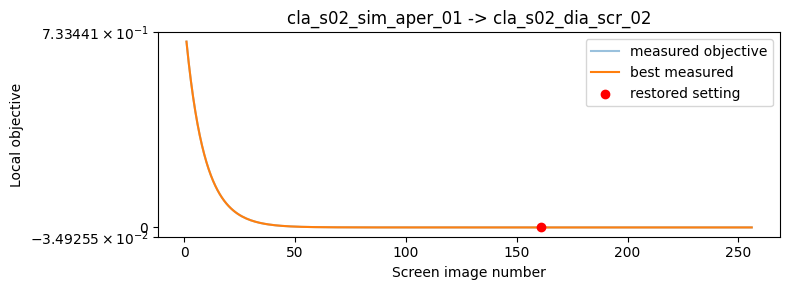

[3/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_03: 11 knobs; building ideal response
  [3/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_03: image 1/256, objective 1.255, best measured 1.255, exit transmission 100.0%
  [3/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_03: image 16/256, objective 0.2562, best measured 0.2562, exit transmission 100.0%
  [3/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_03: image 32/256, objective 0.04735, best measured 0.04735, exit transmission 100.0%
  [3/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_03: image 48/256, objective 0.00878, best measured 0.00878, exit transmission 100.0%
  [3/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_03: image 64/256, objective 0.00163, best measured 0.00163, exit transmission 100.0%
  [3/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_03: image 80/256, objective 0.0003007, best measured 0.0003007, exit transmission 100.0%
  [3/23] cla_s02_sim_aper_01 -> cla_s02_dia_scr_03: image 96/256, objective 5.466e-05, best measured 5.466e-05, exit tran

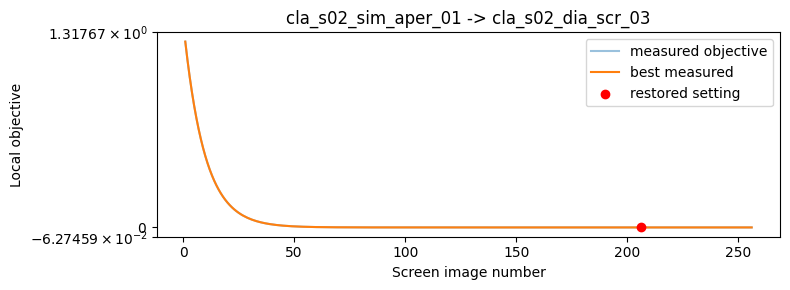

[4/23] cla_s02_dia_scr_02 -> cla_s03_dia_scr_01: 8 knobs; building ideal response
  [4/23] cla_s02_dia_scr_02 -> cla_s03_dia_scr_01: image 1/256, objective 3.233, best measured 3.233, exit transmission 100.0%
  [4/23] cla_s02_dia_scr_02 -> cla_s03_dia_scr_01: image 16/256, objective 0.2768, best measured 0.2768, exit transmission 100.0%
  [4/23] cla_s02_dia_scr_02 -> cla_s03_dia_scr_01: image 32/256, objective 0.005454, best measured 0.005454, exit transmission 99.9%
  [4/23] cla_s02_dia_scr_02 -> cla_s03_dia_scr_01: image 48/256, objective 0.006775, best measured 0.005454, exit transmission 99.9%
  [4/23] cla_s02_dia_scr_02 -> cla_s03_dia_scr_01: image 64/256, objective 0.003286, best measured 0.003286, exit transmission 99.9%
  [4/23] cla_s02_dia_scr_02 -> cla_s03_dia_scr_01: image 80/256, objective 0.0008564, best measured 0.0008564, exit transmission 99.9%
  [4/23] cla_s02_dia_scr_02 -> cla_s03_dia_scr_01: image 96/256, objective 0.0002028, best measured 0.0002028, exit transmissio

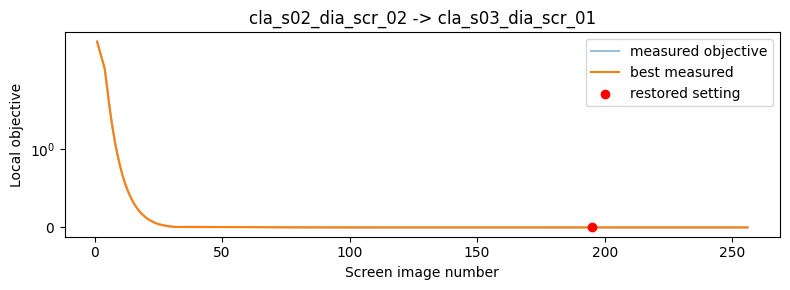

[5/23] cla_s02_dia_scr_02 -> cla_s04_dia_scr_01: 12 knobs; building ideal response
  [5/23] cla_s02_dia_scr_02 -> cla_s04_dia_scr_01: image 1/256, objective 0.9173, best measured 0.9173, exit transmission 99.3%
  [5/23] cla_s02_dia_scr_02 -> cla_s04_dia_scr_01: image 16/256, objective 0.2573, best measured 0.2573, exit transmission 99.2%
  [5/23] cla_s02_dia_scr_02 -> cla_s04_dia_scr_01: image 32/256, objective 0.09518, best measured 0.09518, exit transmission 99.2%
  [5/23] cla_s02_dia_scr_02 -> cla_s04_dia_scr_01: image 48/256, objective 0.04198, best measured 0.04198, exit transmission 99.2%
  [5/23] cla_s02_dia_scr_02 -> cla_s04_dia_scr_01: image 64/256, objective 0.02094, best measured 0.02094, exit transmission 99.2%
  [5/23] cla_s02_dia_scr_02 -> cla_s04_dia_scr_01: image 80/256, objective 0.01034, best measured 0.01034, exit transmission 99.2%
  [5/23] cla_s02_dia_scr_02 -> cla_s04_dia_scr_01: image 96/256, objective 0.003588, best measured 0.003588, exit transmission 99.2%
  [

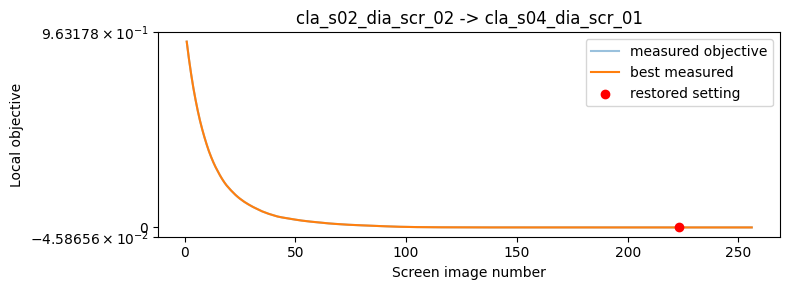

[6/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_02: 8 knobs; building ideal response
  [6/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_02: image 1/256, objective 0.5335, best measured 0.5335, exit transmission 99.2%
  [6/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_02: image 16/256, objective 0.1085, best measured 0.1085, exit transmission 99.2%
  [6/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_02: image 32/256, objective 0.01994, best measured 0.01994, exit transmission 99.2%
  [6/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_02: image 48/256, objective 0.0035, best measured 0.0035, exit transmission 99.2%
  [6/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_02: image 64/256, objective 0.002611, best measured 0.002611, exit transmission 99.2%
  [6/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_02: image 80/256, objective 0.001681, best measured 0.001681, exit transmission 99.2%
  [6/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_02: image 96/256, objective 0.00131, best measured 0.00131, exit transmission 99.2%
  [6

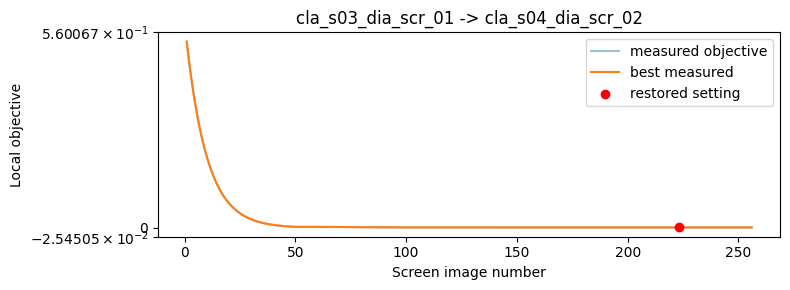

[7/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_03: 8 knobs; building ideal response
  [7/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_03: image 1/256, objective 0.154, best measured 0.154, exit transmission 99.2%
  [7/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_03: image 16/256, objective 0.04251, best measured 0.04251, exit transmission 99.2%
  [7/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_03: image 32/256, objective 0.01234, best measured 0.01234, exit transmission 99.2%
  [7/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_03: image 48/256, objective 0.004567, best measured 0.004567, exit transmission 99.2%
  [7/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_03: image 64/256, objective 0.002492, best measured 0.002492, exit transmission 99.2%
  [7/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_03: image 80/256, objective 0.001973, best measured 0.001973, exit transmission 99.2%
  [7/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_03: image 96/256, objective 0.001848, best measured 0.001848, exit transmission 99.2

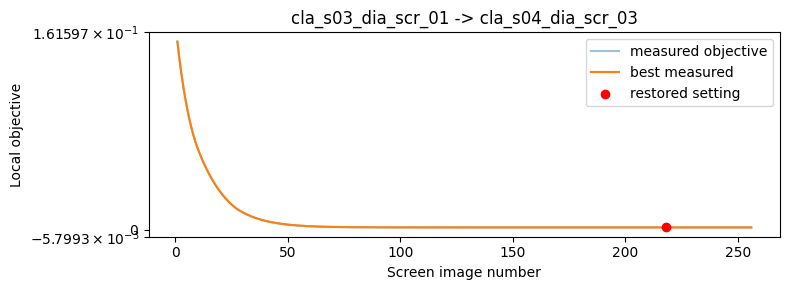

[8/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_04: 10 knobs; building ideal response
  [8/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_04: image 1/256, objective 0.2018, best measured 0.2018, exit transmission 99.2%
  [8/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_04: image 16/256, objective 0.05353, best measured 0.05353, exit transmission 99.2%
  [8/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_04: image 32/256, objective 0.01548, best measured 0.01548, exit transmission 99.2%
  [8/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_04: image 48/256, objective 0.006574, best measured 0.006574, exit transmission 99.2%
  [8/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_04: image 64/256, objective 0.004369, best measured 0.004369, exit transmission 99.2%
  [8/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_04: image 80/256, objective 0.003833, best measured 0.003833, exit transmission 99.2%
  [8/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_04: image 96/256, objective 0.003705, best measured 0.003705, exit transmission 9

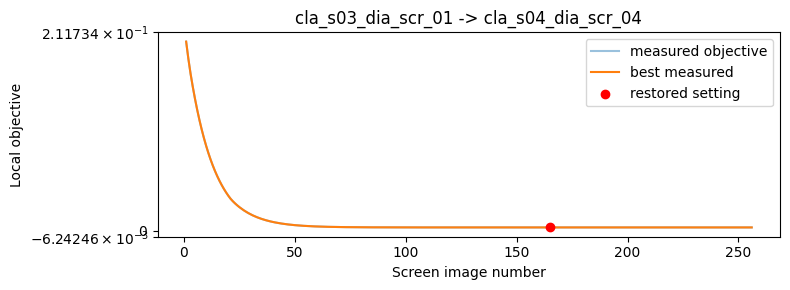

[9/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_05: 10 knobs; building ideal response
  [9/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_05: image 1/256, objective 0.09233, best measured 0.09233, exit transmission 99.2%
  [9/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_05: image 16/256, objective 0.02667, best measured 0.02667, exit transmission 99.2%
  [9/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_05: image 32/256, objective 0.01042, best measured 0.01042, exit transmission 99.2%
  [9/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_05: image 48/256, objective 0.00634, best measured 0.00634, exit transmission 99.2%
  [9/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_05: image 64/256, objective 0.005332, best measured 0.005332, exit transmission 99.2%
  [9/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_05: image 80/256, objective 0.005086, best measured 0.005086, exit transmission 99.2%
  [9/23] cla_s03_dia_scr_01 -> cla_s04_dia_scr_05: image 96/256, objective 0.005027, best measured 0.005027, exit transmission 9

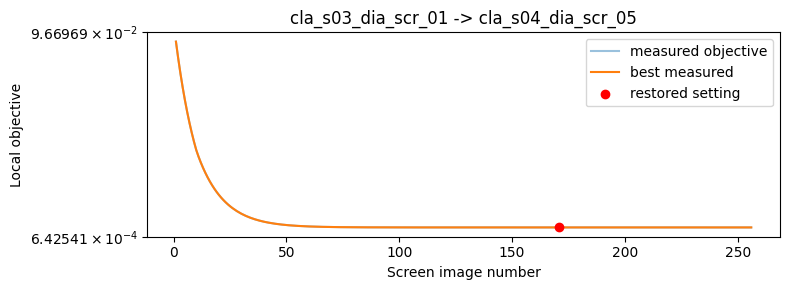

[10/23] cla_s04_dia_scr_05 -> cla_s05_dia_scr_01: 11 knobs; building ideal response
  [10/23] cla_s04_dia_scr_05 -> cla_s05_dia_scr_01: image 1/256, objective 2.011, best measured 2.011, exit transmission 73.7%
  [10/23] cla_s04_dia_scr_05 -> cla_s05_dia_scr_01: image 16/256, objective 0.4112, best measured 0.4112, exit transmission 73.8%
  [10/23] cla_s04_dia_scr_05 -> cla_s05_dia_scr_01: image 32/256, objective 0.07441, best measured 0.07441, exit transmission 73.9%
  [10/23] cla_s04_dia_scr_05 -> cla_s05_dia_scr_01: image 48/256, objective 0.01284, best measured 0.01284, exit transmission 73.9%
  [10/23] cla_s04_dia_scr_05 -> cla_s05_dia_scr_01: image 64/256, objective 0.002494, best measured 0.002494, exit transmission 73.9%
  [10/23] cla_s04_dia_scr_05 -> cla_s05_dia_scr_01: image 80/256, objective 0.0006273, best measured 0.0005719, exit transmission 73.9%
  [10/23] cla_s04_dia_scr_05 -> cla_s05_dia_scr_01: image 96/256, objective 8.117e-05, best measured 8.117e-05, exit transmis

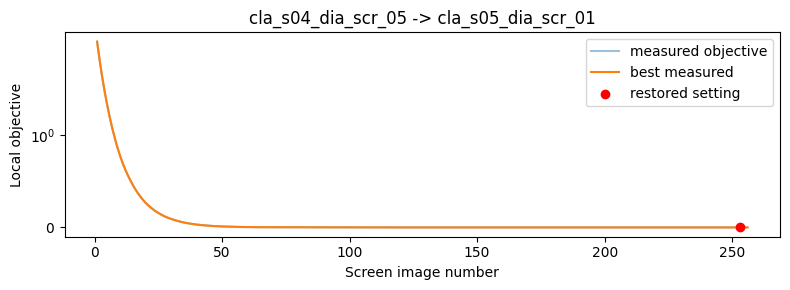

[11/23] cla_s04_dia_scr_05 -> cla_vbc_dia_scr_01: 14 knobs; building ideal response
  [11/23] cla_s04_dia_scr_05 -> cla_vbc_dia_scr_01: image 1/256, objective 0.4239, best measured 0.4239, exit transmission 73.9%
  [11/23] cla_s04_dia_scr_05 -> cla_vbc_dia_scr_01: image 16/256, objective 0.3282, best measured 0.3282, exit transmission 88.7%
  [11/23] cla_s04_dia_scr_05 -> cla_vbc_dia_scr_01: image 32/256, objective 0.1425, best measured 0.1425, exit transmission 88.9%
  [11/23] cla_s04_dia_scr_05 -> cla_vbc_dia_scr_01: image 48/256, objective 0.06821, best measured 0.06821, exit transmission 88.8%
  [11/23] cla_s04_dia_scr_05 -> cla_vbc_dia_scr_01: image 64/256, objective 0.03939, best measured 0.03939, exit transmission 88.8%
  [11/23] cla_s04_dia_scr_05 -> cla_vbc_dia_scr_01: image 80/256, objective 0.02915, best measured 0.02915, exit transmission 88.8%
  [11/23] cla_s04_dia_scr_05 -> cla_vbc_dia_scr_01: image 96/256, objective 0.02575, best measured 0.02575, exit transmission 88.8%

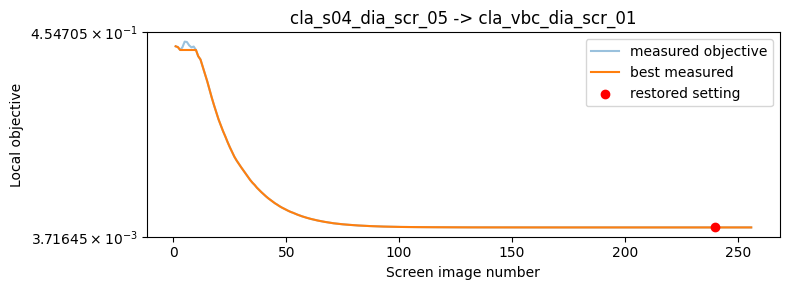

[12/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_01: 18 knobs; building ideal response
  [12/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_01: image 1/256, objective 0.6818, best measured 0.6818, exit transmission 88.8%
  [12/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_01: image 16/256, objective 0.2044, best measured 0.2044, exit transmission 89.6%
  [12/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_01: image 32/256, objective 0.08864, best measured 0.08864, exit transmission 89.9%
  [12/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_01: image 48/256, objective 0.04098, best measured 0.04098, exit transmission 90.0%
  [12/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_01: image 64/256, objective 0.01757, best measured 0.01757, exit transmission 90.0%
  [12/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_01: image 80/256, objective 0.006987, best measured 0.006987, exit transmission 90.0%
  [12/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_01: image 96/256, objective 0.00339, best measured 0.00339, exit transmission 9

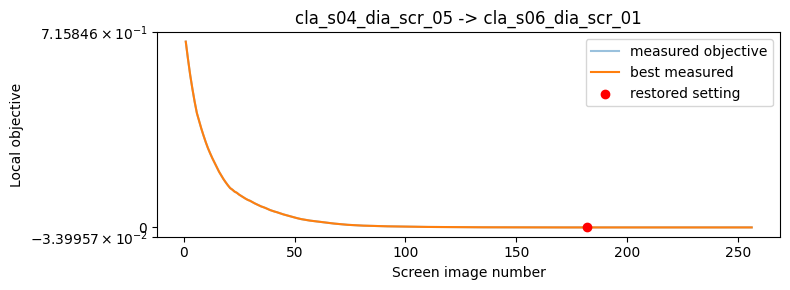

[13/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_02: 20 knobs; building ideal response
  [13/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_02: image 1/256, objective 0.4111, best measured 0.4111, exit transmission 90.0%
  [13/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_02: image 16/256, objective 0.1456, best measured 0.1456, exit transmission 89.8%
  [13/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_02: image 32/256, objective 0.03583, best measured 0.03583, exit transmission 89.8%
  [13/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_02: image 48/256, objective 0.006652, best measured 0.006652, exit transmission 89.8%
  [13/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_02: image 64/256, objective 0.003436, best measured 0.003436, exit transmission 89.8%
  [13/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_02: image 80/256, objective 0.002147, best measured 0.002147, exit transmission 89.8%
  [13/23] cla_s04_dia_scr_05 -> cla_s06_dia_scr_02: image 96/256, objective 0.001111, best measured 0.001111, exit transmis

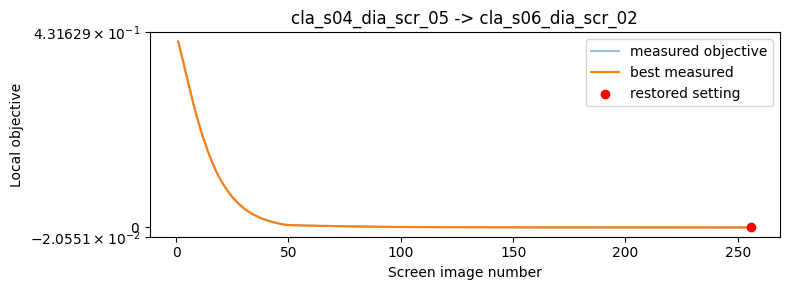

[14/23] cla_vbc_dia_scr_01 -> cla_s07_dia_scr_01: 12 knobs; building ideal response
  [14/23] cla_vbc_dia_scr_01 -> cla_s07_dia_scr_01: image 1/256, objective 2.977, best measured 2.977, exit transmission 89.8%
  [14/23] cla_vbc_dia_scr_01 -> cla_s07_dia_scr_01: image 16/256, objective 0.5398, best measured 0.5398, exit transmission 89.8%
  [14/23] cla_vbc_dia_scr_01 -> cla_s07_dia_scr_01: image 32/256, objective 0.106, best measured 0.106, exit transmission 89.8%
  [14/23] cla_vbc_dia_scr_01 -> cla_s07_dia_scr_01: image 48/256, objective 0.02442, best measured 0.02442, exit transmission 89.8%
  [14/23] cla_vbc_dia_scr_01 -> cla_s07_dia_scr_01: image 64/256, objective 0.007493, best measured 0.007493, exit transmission 89.8%
  [14/23] cla_vbc_dia_scr_01 -> cla_s07_dia_scr_01: image 80/256, objective 0.00251, best measured 0.00251, exit transmission 89.8%
  [14/23] cla_vbc_dia_scr_01 -> cla_s07_dia_scr_01: image 96/256, objective 0.0007747, best measured 0.0007747, exit transmission 89.

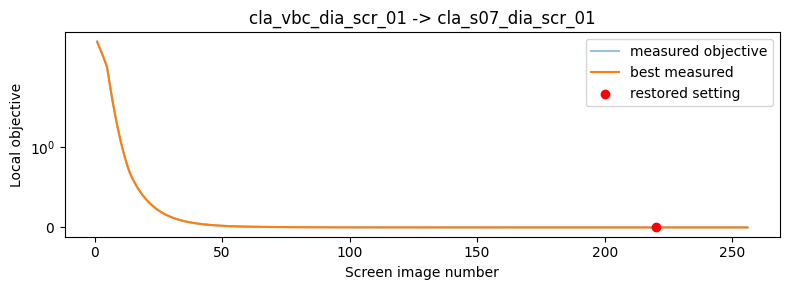

[15/23] cla_s06_dia_scr_02 -> cla_s07_dia_scr_02: 10 knobs; building ideal response
  [15/23] cla_s06_dia_scr_02 -> cla_s07_dia_scr_02: image 1/256, objective 0.2922, best measured 0.2922, exit transmission 66.9%
  [15/23] cla_s06_dia_scr_02 -> cla_s07_dia_scr_02: image 16/256, objective 0.205, best measured 0.1889, exit transmission 69.0%
  [15/23] cla_s06_dia_scr_02 -> cla_s07_dia_scr_02: image 32/256, objective 0.09776, best measured 0.09776, exit transmission 76.1%
  [15/23] cla_s06_dia_scr_02 -> cla_s07_dia_scr_02: image 48/256, objective 0.01702, best measured 0.01702, exit transmission 77.4%
  [15/23] cla_s06_dia_scr_02 -> cla_s07_dia_scr_02: image 64/256, objective 0.003094, best measured 0.003094, exit transmission 77.6%
  [15/23] cla_s06_dia_scr_02 -> cla_s07_dia_scr_02: image 80/256, objective 0.0007797, best measured 0.0007146, exit transmission 77.6%
  [15/23] cla_s06_dia_scr_02 -> cla_s07_dia_scr_02: image 96/256, objective 0.0001356, best measured 0.0001356, exit transmi

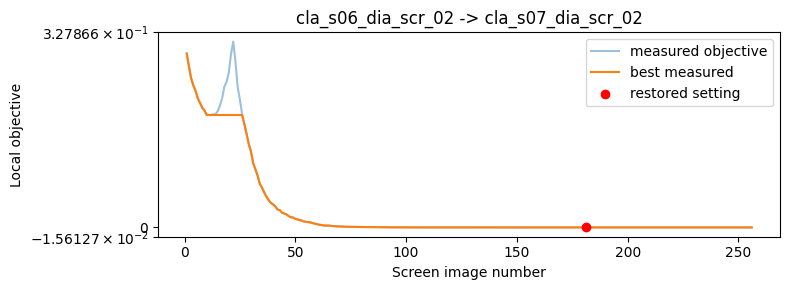

[16/23] cla_s07_dia_scr_01 -> cla_s07_dcp_scr_01: 8 knobs; building ideal response
  [16/23] cla_s07_dia_scr_01 -> cla_s07_dcp_scr_01: image 1/256, objective 0.2938, best measured 0.2938, exit transmission 77.6%
  [16/23] cla_s07_dia_scr_01 -> cla_s07_dcp_scr_01: image 16/256, objective 0.1038, best measured 0.08731, exit transmission 77.6%
  [16/23] cla_s07_dia_scr_01 -> cla_s07_dcp_scr_01: image 32/256, objective 0.303, best measured 0.08731, exit transmission 77.6%
  [16/23] cla_s07_dia_scr_01 -> cla_s07_dcp_scr_01: image 48/256, objective 0.3084, best measured 0.08731, exit transmission 77.6%
  [16/23] cla_s07_dia_scr_01 -> cla_s07_dcp_scr_01: image 64/256, objective 0.2838, best measured 0.08731, exit transmission 77.6%
  [16/23] cla_s07_dia_scr_01 -> cla_s07_dcp_scr_01: image 80/256, objective 0.2752, best measured 0.08731, exit transmission 77.6%
  [16/23] cla_s07_dia_scr_01 -> cla_s07_dcp_scr_01: image 96/256, objective 0.273, best measured 0.08731, exit transmission 77.6%
  [1

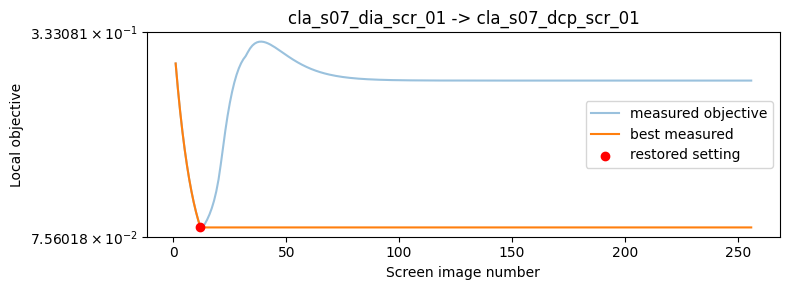

[17/23] cla_s07_dia_scr_01 -> cla_s07_dia_scr_03: 13 knobs; building ideal response
  [17/23] cla_s07_dia_scr_01 -> cla_s07_dia_scr_03: image 1/256, objective 1.023, best measured 1.023, exit transmission 77.6%
  [17/23] cla_s07_dia_scr_01 -> cla_s07_dia_scr_03: image 16/256, objective 1.183, best measured 0.8736, exit transmission 77.6%
  [17/23] cla_s07_dia_scr_01 -> cla_s07_dia_scr_03: image 32/256, objective 0.3313, best measured 0.3313, exit transmission 77.6%
  [17/23] cla_s07_dia_scr_01 -> cla_s07_dia_scr_03: image 48/256, objective 0.5679, best measured 0.2843, exit transmission 77.6%
  [17/23] cla_s07_dia_scr_01 -> cla_s07_dia_scr_03: image 64/256, objective 0.9097, best measured 0.2843, exit transmission 77.6%
  [17/23] cla_s07_dia_scr_01 -> cla_s07_dia_scr_03: image 80/256, objective 1.42, best measured 0.2843, exit transmission 77.6%
  [17/23] cla_s07_dia_scr_01 -> cla_s07_dia_scr_03: image 96/256, objective 1.769, best measured 0.2843, exit transmission 77.6%
  [17/23] cla

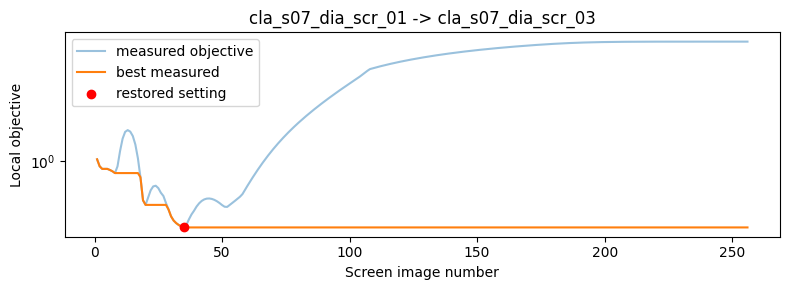

[18/23] cla_s07_dia_scr_02 -> cla_s07_dia_scr_04: 13 knobs; building ideal response
  [18/23] cla_s07_dia_scr_02 -> cla_s07_dia_scr_04: image 1/256, objective 1.882, best measured 1.882, exit transmission 77.6%
  [18/23] cla_s07_dia_scr_02 -> cla_s07_dia_scr_04: image 16/256, objective 2.949, best measured 1.882, exit transmission 77.6%
  [18/23] cla_s07_dia_scr_02 -> cla_s07_dia_scr_04: image 32/256, objective 4.869, best measured 1.882, exit transmission 77.6%
  [18/23] cla_s07_dia_scr_02 -> cla_s07_dia_scr_04: image 48/256, objective 7.371, best measured 1.882, exit transmission 77.6%
  [18/23] cla_s07_dia_scr_02 -> cla_s07_dia_scr_04: image 64/256, objective 9.555, best measured 1.882, exit transmission 77.6%
  [18/23] cla_s07_dia_scr_02 -> cla_s07_dia_scr_04: image 80/256, objective 10.61, best measured 1.882, exit transmission 77.6%
  [18/23] cla_s07_dia_scr_02 -> cla_s07_dia_scr_04: image 96/256, objective 11.07, best measured 1.882, exit transmission 77.6%
  [18/23] cla_s07_dia

In [ ]:
FULL_METHOD = "response matrix"

FULL_FINAL_SCREEN = None  # None: last physical screen; otherwise its exact name
FULL_MAX_SECTIONS = 5 if FAST_RUN else None
FULL_MIN_QUADRUPOLES = 4
FULL_MIN_CORRECTORS = 4  # H/V angles, i.e. normally two combined corrector devices
FULL_BUDGET_PER_SCREEN = MEASUREMENT_BUDGET
FULL_BUDGET_PER_SCREEN = 256

FULL_BEAM_SEVERITY = SCORE_BEAM_SEVERITY
FULL_START_ERROR = START_ERROR_FRACTION
FULL_VERBOSE = True
FULL_LOG_EVERY = 16

from work.nominal_machine import load_lattice as load_full_lattice, load_beam as load_nominal_beam
from work.section_diagnostics import plot_section_convergence, plot_pass_envelopes, plot_exit_beams

FULL_MODEL = "nominal"  # nominal: new recommended lattice-file tune; gpsr: scan tune; scorer: old benchmark
FULL_DETAILED_APERTURES = True
FULL_MODEL_END = "cla_feh_dia_scr_01"  # validated nominal-model extent; None extends to the lattice end
FULL_MISALIGNMENT_SEVERITY = 1.0
FULL_PLOT_EACH_SECTION = True
# Keep the user's production 512-image budget; smoke runs use six images.
if FAST_RUN:
    FULL_BUDGET_PER_SCREEN = min(FULL_BUDGET_PER_SCREEN, 6)

reference_machine = load_full_lattice(model=FULL_MODEL, errors=False,
    apertures=FULL_DETAILED_APERTURES, end=FULL_MODEL_END)
full_machine = load_full_lattice(model=FULL_MODEL, errors=True, seed=SEED+9001,
    setpoint_fraction=FULL_START_ERROR, misalignment_severity=FULL_MISALIGNMENT_SEVERITY,
    apertures=FULL_DETAILED_APERTURES, end=FULL_MODEL_END)
if FULL_MODEL == "scorer":
    ideal_root = sample_score_beam(np.random.default_rng(SEED), num_particles=NUM_PARTICLES, severity=0.)
    actual_root = sample_score_beam(np.random.default_rng(SEED+9000), num_particles=NUM_PARTICLES, severity=FULL_BEAM_SEVERITY)
    from work.beamline_tuning import input_boundary_name
    full_input_name = input_boundary_name(reference_machine)
else:
    # Use the same sampled base particles for model and plant, then add explicit injection jitter.
    ideal_root = load_nominal_beam(NUM_PARTICLES, seed=SEED, severity=0.)
    actual_root = load_nominal_beam(NUM_PARTICLES, seed=SEED, severity=FULL_BEAM_SEVERITY)
    full_input_name = "cla_s02_sim_aper_01"
full_plot_screen = FULL_FINAL_SCREEN or FULL_MODEL_END or "cla_feh_dia_scr_01"
print({"model": FULL_MODEL, "input beam": full_input_name,
       "detailed apertures": FULL_DETAILED_APERTURES, "misalignment severity": FULL_MISALIGNMENT_SEVERITY})
full_plans = plan_screen_sequence(reference_machine, input_screen=full_input_name,
    min_quadrupoles=FULL_MIN_QUADRUPOLES, min_correctors=FULL_MIN_CORRECTORS,
    final_screen=FULL_FINAL_SCREEN, max_sections=FULL_MAX_SECTIONS)
plan_table = pd.DataFrame([dict(input_screen=p.input_screen, output_screen=p.output_screen,
    quadrupoles=sum(k.kind=="quadrupole" for k in p.knobs),
    corrector_angles=sum(k.kind=="corrector" for k in p.knobs)) for p in full_plans])
plan_table["enough_controls"] = ((plan_table.quadrupoles >= FULL_MIN_QUADRUPOLES)
                                  & (plan_table.corrector_angles >= FULL_MIN_CORRECTORS))
display(plan_table)
full_run = correct_screen_sequence(full_machine, reference_machine, actual_root, ideal_root, full_plans,
    verbose=FULL_VERBOSE, log_every=FULL_LOG_EVERY,
    section_callback=plot_section_convergence if FULL_PLOT_EACH_SECTION else None,
    method=FULL_METHOD, budget=FULL_BUDGET_PER_SCREEN, noise_fraction=READOUT_NOISE, seed=SEED+9100,
    response_step=RESPONSE_STEP, learning_rate=RESPONSE_LEARNING_RATE,
    response_mode=RESPONSE_SOLVE_MODE, ridge=RESPONSE_RIDGE,
    direction_mode=DIRECTION_MODE, rcds_bo_options=RCDS_BO_OPTIONS,
    bo_options=dict(acquisition=FULL_BO_ACQUISITION, switch_at=FULL_BO_SWITCH_AT, beta=BO_UCB_BETA))
full_steps = pd.DataFrame(full_run["records"])
full_audit = pd.DataFrame(full_run["audit"])
# Reports in percent; raw fractional values remain in full_steps and full_audit.
def transmission_report(frame):
    report = frame.copy()
    for column in list(report.columns):
        if "transmission" in column:
            report[column + "_pct"] = 100 * report.pop(column)
    return report

full_section_report = transmission_report(full_steps)
full_final_report = transmission_report(full_audit)
print("Per-section correction report (at the time each window was corrected)")
display(full_section_report[["input_screen", "output_screen", "status", "knobs", "online_measurements",
    "initial_objective", "corrected_objective", "selected_evaluation", "best_measured_objective", "input_transmission_pct",
    "initial_transmission_pct", "corrected_transmission_pct",
    "initial_section_transmission_pct", "corrected_section_transmission_pct", "elapsed_seconds"]])
print("Final audit (after all overlapping corrections)")
display(full_final_report[["screen", "status", "initial_objective", "final_objective",
    "initial_transmission_pct", "final_transmission_pct", "final_section_transmission_pct"]])
print({"online images": full_run["online_measurements"],
       "offline model tracks (upper bound)": full_run["offline_response_tracks_upper_bound"],
       "elapsed seconds": full_run["elapsed_seconds"],
       "end-of-lattice transmission [%]": 100 * full_run["final_transmission"]})
full_report_dir = ROOT / "work" / "experiment_outputs"
if FAST_RUN:
    full_report_dir = full_report_dir / "section_smoke"
full_report_dir.mkdir(parents=True, exist_ok=True)
full_section_report.to_csv(full_report_dir / "full_correction_sections.csv", index=False)
full_final_report.to_csv(full_report_dir / "full_correction_final_audit.csv", index=False)
print("Saved reports to", full_report_dir)
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
full_audit.plot(x="screen", y=["initial_objective", "final_objective"], marker="o", ax=axes[0], logy=True)
axes[0].set_ylabel("Local objective (clean diagnostic)")
full_final_report.plot(x="screen", y=["initial_transmission_pct", "final_transmission_pct"], marker="o", ax=axes[1])
axes[1].set_ylabel("Transmission from input [%]")
axes[1].set_ylim(0, 105)
plt.xticks(rotation=75, ha="right")
plt.tight_layout()

full_passes = [full_run]
full_envelopes = plot_pass_envelopes(full_run, reference_machine, actual_root, ideal_root, title="First correction pass")
plot_exit_beams(full_run, reference_machine, actual_root, ideal_root, full_plot_screen)


The model/beam/aperture investigation and diagnostic plots are integrated above.
The envelope plots include the aperture limits loaded into the simulation. Per-section plots mark
the best measured setting restored before proceeding. The next cell continues from that machine.

In [ ]:
# Continue from pass 1: no reload, no fresh setting errors, no new input beam.
# Rerunning this cell performs another pass from the current corrected machine.
pass_number = len(full_passes) + 1
second_pass = correct_screen_sequence(full_machine, reference_machine, actual_root, ideal_root, full_plans,
    verbose=FULL_VERBOSE, log_every=FULL_LOG_EVERY,
    section_callback=plot_section_convergence if FULL_PLOT_EACH_SECTION else None,
    method=FULL_METHOD, budget=FULL_BUDGET_PER_SCREEN, noise_fraction=READOUT_NOISE,
    seed=SEED+9100+1000*(pass_number-1), response_step=RESPONSE_STEP,
    learning_rate=RESPONSE_LEARNING_RATE, response_mode=RESPONSE_SOLVE_MODE, ridge=RESPONSE_RIDGE,
    direction_mode=DIRECTION_MODE, rcds_bo_options=RCDS_BO_OPTIONS,
    bo_options=dict(acquisition=FULL_BO_ACQUISITION, switch_at=FULL_BO_SWITCH_AT, beta=BO_UCB_BETA))
full_passes.append(second_pass)
display(transmission_report(pd.DataFrame(second_pass["records"])))
display(transmission_report(pd.DataFrame(second_pass["audit"])))
plot_pass_envelopes(second_pass, reference_machine, actual_root, ideal_root,
                    title=f"Pass {pass_number}: previous corrected machine -> next correction")
plot_exit_beams(second_pass, reference_machine, actual_root, ideal_root, full_plot_screen)
transmission_report(pd.DataFrame(second_pass["records"])).to_csv(
    full_report_dir / f"full_correction_pass_{pass_number}_sections.csv", index=False)
transmission_report(pd.DataFrame(second_pass["audit"])).to_csv(
    full_report_dir / f"full_correction_pass_{pass_number}_audit.csv", index=False)
print({"pass": pass_number, "pass images": second_pass["online_measurements"],
       "total images across passes": sum(r["online_measurements"] for r in full_passes),
       "end transmission [%]": 100*second_pass["final_transmission"]})


In [ ]:
FULL_METHOD = "RCDS+BO"  # any entry in METHODS (section-specific PPO is not reusable here)

FULL_FINAL_SCREEN = None  # None: last physical screen; otherwise its exact name
FULL_MAX_SECTIONS = 5 if FAST_RUN else None
FULL_MIN_QUADRUPOLES = 4
FULL_MIN_CORRECTORS = 4  # H/V angles, i.e. normally two combined corrector devices
FULL_BUDGET_PER_SCREEN = MEASUREMENT_BUDGET
FULL_BUDGET_PER_SCREEN = 256

FULL_BEAM_SEVERITY = SCORE_BEAM_SEVERITY
FULL_START_ERROR = START_ERROR_FRACTION
FULL_VERBOSE = True
FULL_LOG_EVERY = 16

from work.nominal_machine import load_lattice as load_full_lattice, load_beam as load_nominal_beam
from work.section_diagnostics import plot_section_convergence, plot_pass_envelopes, plot_exit_beams

FULL_MODEL = "nominal"  # nominal: new recommended lattice-file tune; gpsr: scan tune; scorer: old benchmark
FULL_DETAILED_APERTURES = True
FULL_MODEL_END = "cla_feh_dia_scr_01"  # validated nominal-model extent; None extends to the lattice end
FULL_MISALIGNMENT_SEVERITY = 1.0
FULL_PLOT_EACH_SECTION = True
# Keep the user's production 512-image budget; smoke runs use six images.
if FAST_RUN:
    FULL_BUDGET_PER_SCREEN = min(FULL_BUDGET_PER_SCREEN, 6)

reference_machine = load_full_lattice(model=FULL_MODEL, errors=False,
    apertures=FULL_DETAILED_APERTURES, end=FULL_MODEL_END)
full_machine = load_full_lattice(model=FULL_MODEL, errors=True, seed=SEED+9001,
    setpoint_fraction=FULL_START_ERROR, misalignment_severity=FULL_MISALIGNMENT_SEVERITY,
    apertures=FULL_DETAILED_APERTURES, end=FULL_MODEL_END)
if FULL_MODEL == "scorer":
    ideal_root = sample_score_beam(np.random.default_rng(SEED), num_particles=NUM_PARTICLES, severity=0.)
    actual_root = sample_score_beam(np.random.default_rng(SEED+9000), num_particles=NUM_PARTICLES, severity=FULL_BEAM_SEVERITY)
    from work.beamline_tuning import input_boundary_name
    full_input_name = input_boundary_name(reference_machine)
else:
    # Use the same sampled base particles for model and plant, then add explicit injection jitter.
    ideal_root = load_nominal_beam(NUM_PARTICLES, seed=SEED, severity=0.)
    actual_root = load_nominal_beam(NUM_PARTICLES, seed=SEED, severity=FULL_BEAM_SEVERITY)
    full_input_name = "cla_s02_sim_aper_01"
full_plot_screen = FULL_FINAL_SCREEN or FULL_MODEL_END or "cla_feh_dia_scr_01"
print({"model": FULL_MODEL, "input beam": full_input_name,
       "detailed apertures": FULL_DETAILED_APERTURES, "misalignment severity": FULL_MISALIGNMENT_SEVERITY})
full_plans = plan_screen_sequence(reference_machine, input_screen=full_input_name,
    min_quadrupoles=FULL_MIN_QUADRUPOLES, min_correctors=FULL_MIN_CORRECTORS,
    final_screen=FULL_FINAL_SCREEN, max_sections=FULL_MAX_SECTIONS)
plan_table = pd.DataFrame([dict(input_screen=p.input_screen, output_screen=p.output_screen,
    quadrupoles=sum(k.kind=="quadrupole" for k in p.knobs),
    corrector_angles=sum(k.kind=="corrector" for k in p.knobs)) for p in full_plans])
plan_table["enough_controls"] = ((plan_table.quadrupoles >= FULL_MIN_QUADRUPOLES)
                                  & (plan_table.corrector_angles >= FULL_MIN_CORRECTORS))
display(plan_table)
full_run = correct_screen_sequence(full_machine, reference_machine, actual_root, ideal_root, full_plans,
    verbose=FULL_VERBOSE, log_every=FULL_LOG_EVERY,
    section_callback=plot_section_convergence if FULL_PLOT_EACH_SECTION else None,
    method=FULL_METHOD, budget=FULL_BUDGET_PER_SCREEN, noise_fraction=READOUT_NOISE, seed=SEED+9100,
    response_step=RESPONSE_STEP, learning_rate=RESPONSE_LEARNING_RATE,
    response_mode=RESPONSE_SOLVE_MODE, ridge=RESPONSE_RIDGE,
    direction_mode=DIRECTION_MODE, rcds_bo_options=RCDS_BO_OPTIONS,
    bo_options=dict(acquisition=FULL_BO_ACQUISITION, switch_at=FULL_BO_SWITCH_AT, beta=BO_UCB_BETA))
full_steps = pd.DataFrame(full_run["records"])
full_audit = pd.DataFrame(full_run["audit"])
# Reports in percent; raw fractional values remain in full_steps and full_audit.
def transmission_report(frame):
    report = frame.copy()
    for column in list(report.columns):
        if "transmission" in column:
            report[column + "_pct"] = 100 * report.pop(column)
    return report

full_section_report = transmission_report(full_steps)
full_final_report = transmission_report(full_audit)
print("Per-section correction report (at the time each window was corrected)")
display(full_section_report[["input_screen", "output_screen", "status", "knobs", "online_measurements",
    "initial_objective", "corrected_objective", "selected_evaluation", "best_measured_objective", "input_transmission_pct",
    "initial_transmission_pct", "corrected_transmission_pct",
    "initial_section_transmission_pct", "corrected_section_transmission_pct", "elapsed_seconds"]])
print("Final audit (after all overlapping corrections)")
display(full_final_report[["screen", "status", "initial_objective", "final_objective",
    "initial_transmission_pct", "final_transmission_pct", "final_section_transmission_pct"]])
print({"online images": full_run["online_measurements"],
       "offline model tracks (upper bound)": full_run["offline_response_tracks_upper_bound"],
       "elapsed seconds": full_run["elapsed_seconds"],
       "end-of-lattice transmission [%]": 100 * full_run["final_transmission"]})
full_report_dir = ROOT / "work" / "experiment_outputs"
if FAST_RUN:
    full_report_dir = full_report_dir / "section_smoke"
full_report_dir.mkdir(parents=True, exist_ok=True)
full_section_report.to_csv(full_report_dir / "full_correction_sections.csv", index=False)
full_final_report.to_csv(full_report_dir / "full_correction_final_audit.csv", index=False)
print("Saved reports to", full_report_dir)
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
full_audit.plot(x="screen", y=["initial_objective", "final_objective"], marker="o", ax=axes[0], logy=True)
axes[0].set_ylabel("Local objective (clean diagnostic)")
full_final_report.plot(x="screen", y=["initial_transmission_pct", "final_transmission_pct"], marker="o", ax=axes[1])
axes[1].set_ylabel("Transmission from input [%]")
axes[1].set_ylim(0, 105)
plt.xticks(rotation=75, ha="right")
plt.tight_layout()

full_passes = [full_run]
full_envelopes = plot_pass_envelopes(full_run, reference_machine, actual_root, ideal_root, title="First correction pass")
plot_exit_beams(full_run, reference_machine, actual_root, ideal_root, full_plot_screen)


In [ ]:
# Continue from pass 1: no reload, no fresh setting errors, no new input beam.
# Rerunning this cell performs another pass from the current corrected machine.
pass_number = len(full_passes) + 1
second_pass = correct_screen_sequence(full_machine, reference_machine, actual_root, ideal_root, full_plans,
    verbose=FULL_VERBOSE, log_every=FULL_LOG_EVERY,
    section_callback=plot_section_convergence if FULL_PLOT_EACH_SECTION else None,
    method=FULL_METHOD, budget=FULL_BUDGET_PER_SCREEN, noise_fraction=READOUT_NOISE,
    seed=SEED+9100+1000*(pass_number-1), response_step=RESPONSE_STEP,
    learning_rate=RESPONSE_LEARNING_RATE, response_mode=RESPONSE_SOLVE_MODE, ridge=RESPONSE_RIDGE,
    direction_mode=DIRECTION_MODE, rcds_bo_options=RCDS_BO_OPTIONS,
    bo_options=dict(acquisition=FULL_BO_ACQUISITION, switch_at=FULL_BO_SWITCH_AT, beta=BO_UCB_BETA))
full_passes.append(second_pass)
display(transmission_report(pd.DataFrame(second_pass["records"])))
display(transmission_report(pd.DataFrame(second_pass["audit"])))
plot_pass_envelopes(second_pass, reference_machine, actual_root, ideal_root,
                    title=f"Pass {pass_number}: previous corrected machine -> next correction")
plot_exit_beams(second_pass, reference_machine, actual_root, ideal_root, full_plot_screen)
transmission_report(pd.DataFrame(second_pass["records"])).to_csv(
    full_report_dir / f"full_correction_pass_{pass_number}_sections.csv", index=False)
transmission_report(pd.DataFrame(second_pass["audit"])).to_csv(
    full_report_dir / f"full_correction_pass_{pass_number}_audit.csv", index=False)
print({"pass": pass_number, "pass images": second_pass["online_measurements"],
       "total images across passes": sum(r["online_measurements"] for r in full_passes),
       "end transmission [%]": 100*second_pass["final_transmission"]})
